# Phase 4 – Court Judgment Prediction (CJPE): full experiment notebook

Binary outcome prediction (0/1) for long Indian court judgments, built on your **Phase-1 encoder-decoder** (encoder only) with the same
swappable adaptation methods / logger / submission utilities as the Phase-3 notebook.

**What changed vs. Phase 3.** Phase 3 classified *sentences* inside a document; Phase 4 classifies a *whole judgment*, which is far longer than the encoder's context.
So the sentence→BiGRU hierarchy is replaced by **chunk → pooling → document label**:

`document tokens → windows (head / tail / sliding / …) → Phase-1 encoder → masked mean-pool per window → [+ position features] → aggregator (mean / max / attention / BiGRU+attention) → 2-way logits`

**Long-document representation (`cfg["view"]`, `cfg["pool"]`) – the Section-9 Part A study**

| `view` | windows fed to the encoder |
|---|---|
| `head` / `tail` / `headtail` | first / last / first+last `chunk_len` tokens |
| `sliding` | every window, step `stride` (overlap = `chunk_len-2-stride`), capped at `eval_chunks` |
| `sliding_last` / `sliding_first` / `sliding_headtail` | only the last / first / first+last `k_last` windows (section selection) |

| `pool` | document aggregator |
|---|---|
| `mean`, `max` | parameter-free pooling of window vectors |
| `attn` | learned attention pooling |
| `gru` | hierarchical: BiGRU over the ordered window vectors + attention pooling |

**Adaptation methods (`cfg["method"]`)** – everything from Phase 3 plus the ones Phase 4 lists

| key | method | trainable |
|---|---|---|
| `frozen` | Phase-1 frozen, head only (diagnostic) | head |
| `full` | full fine-tuning | everything |
| `partial` | top-k encoder layers | k layers + head |
| `gradual` | **new** – layer-wise *unfreezing*: head only in epoch 1, then `unfreeze_per_epoch` more layers (top→bottom) each epoch | grows per epoch |
| `lora` / `rslora` | LoRA / rank-stabilised LoRA | adapters + head |
| `lorma` | LoRMA+ (compulsory) | adapters + head |
| `adapter` | **new** – Houlsby-style bottleneck adapters after attention-out and FFN-out | adapters + head |
| `ia3` | IA³ | scales + head |
| `norm` | **new** – BitFit *analogue*: only RMSNorm gains (the Phase-1 model has no biases, so true BitFit has nothing to tune) | norm gains + head |
| `prompt` | prompt tuning | prompt + head |
| KD | `run_cjpe(..., teacher=..., n_layers=k)` – truncated-encoder student distilled from a trained teacher (CE + KL on the 2-way logits) | student |

**Read before running**
* I could not run this on a GPU (no torch in my sandbox). I syntax-checked every cell and unit-tested the pure-Python parts (windowing, metrics, threshold search, loader). Everything torch-side is unexecuted — expect to debug a typo or shape issue on first run, and send me the traceback.
* **I have not seen the Phase-4 files.** The loader accepts a list *or* dict layout and looks for the text/label under several common key names (`TEXT_KEYS`, `LABEL_KEYS` in Section 1). Run the schema cell first and adjust those tuples if your files differ.
* **Compute.** The train split may be tens of thousands of long documents. `docs_per_epoch`, `train_chunks`, `eval_chunks`, `dev_cap` and `SUBSAMPLE_TRAIN` bound the cost; set `SMOKE_TEST = True` first to verify the pipeline in minutes.
* `chunk_len=512` is a guess. If your Phase-1 model was trained on shorter contexts, lower it (the relative-position bias is bucketed so longer inputs run, but quality may degrade).
* The Phase-4 rule says the six required submissions must be **different adaptation techniques**; Part A (representation study) varies *representation only* and does not count towards that.
* AdaLoRA is not implemented (invasive; Phase-4 lists it as optional alongside the others).
* Hyper-parameters in `BASE_CFG` are starting points, not tuned values.

## 1. Config, data, cleaning, metrics, logger, submission utilities

In [ ]:
import os, sys, re, json, random, unicodedata, zipfile, time, math, pickle
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# True -> tiny subsets + 1 epoch to check the whole pipeline end-to-end in a few minutes (its zips are NOT submittable)
SMOKE_TEST = False
# Optional: use only a stratified subset of the (very large) train split everywhere. None = use everything.
SUBSAMPLE_TRAIN = None

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/Phase4_Court_Judgment_Prediction"
else:
    OUTPUT_DIR = "./phase4_outputs"
if SMOKE_TEST: OUTPUT_DIR += "_smoke"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DATA_DIR = "./phase4_cjpe_data"
os.makedirs(DATA_DIR, exist_ok=True)

# NEVER paste a token in the notebook. Use Colab secrets (key name HF_TOKEN) or an env var.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None and IN_COLAB:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        pass
print("Output dir:", OUTPUT_DIR, "| HF token set:", HF_TOKEN is not None, "| SMOKE_TEST:", SMOKE_TEST)

Mounted at /content/drive
Output dir: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction | HF token set: True | SMOKE_TEST: False


In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F, copy, gc, heapq
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED); print("GPU:", torch.cuda.get_device_name(0))
torch.manual_seed(SEED)

# ---- EDIT: Phase-1 artefacts (encoder-decoder run) ----
PHASE1_WORK_DIR = "/content/drive/MyDrive/Phase1_Pretraining/phase1_encoder_decoder"
CHECKPOINT_PATH = os.path.join(PHASE1_WORK_DIR, "checkpoints", "encoder_decoder_best.pt")
TOKENIZER_PATH  = os.path.join(PHASE1_WORK_DIR, "final_bpe_en.json")

GPU: Tesla T4


In [ ]:
from huggingface_hub import hf_hub_download

REPO_ID = "Exploration-Lab/CS-781-Capstone"
PHASE4_FILES = {
    "train": "Phase_4_CJPE/Train/train.json",
    "dev":   "Phase_4_CJPE/Train/dev.json",
    "test":  "Phase_4_CJPE/Test/test.json",
}
raw_data = {}
for key, fn in PHASE4_FILES.items():
    p = hf_hub_download(repo_id=REPO_ID, filename=fn, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
    with open(p, encoding="utf-8") as f:
        raw_data[key] = json.load(f)
    print(key, "->", p, "| top-level type:", type(raw_data[key]).__name__, "| size:", len(raw_data[key]))

Phase_4_CJPE/Train/train.json: reconstructing file:   0%|          |  0.00B /  737MB            

Phase_4_CJPE/Train/train.json: downloading bytes:           |  0.00B            

train -> /content/phase4_cjpe_data/Phase_4_CJPE/Train/train.json | top-level type: list | size: 37387


Phase_4_CJPE/Train/dev.json: reconstructing file:   0%|          |  0.00B / 80.3MB            

Phase_4_CJPE/Train/dev.json: downloading bytes:           |  0.00B            

dev -> /content/phase4_cjpe_data/Phase_4_CJPE/Train/dev.json | top-level type: list | size: 3505


Phase_4_CJPE/Test/test.json: reconstructing file:   0%|          |  0.00B / 35.3MB            

Phase_4_CJPE/Test/test.json: downloading bytes:           |  0.00B            

test -> /content/phase4_cjpe_data/Phase_4_CJPE/Test/test.json | top-level type: list | size: 1517


In [ ]:
# Schema check: look at the real keys before trusting the loader below.
def _peek(raw):
    if isinstance(raw, dict):
        k0 = next(iter(raw)); v0 = raw[k0]
        return {"dict_key_example": k0, "value_type": type(v0).__name__, "value_keys": list(v0)[:8] if isinstance(v0, dict) else None}
    return {"first_item_keys": list(raw[0])[:8] if isinstance(raw[0], dict) else type(raw[0]).__name__}
for k in raw_data: print(k, _peek(raw_data[k]))

train {'first_item_keys': ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']}
dev {'first_item_keys': ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']}
test {'first_item_keys': ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']}


In [ ]:
TEXT_KEYS  = ("text", "document", "case_text", "judgment", "content")     # <- EDIT if your files use another key
LABEL_KEYS = ("label", "labels", "pred", "y", "outcome", "gold")          # <- EDIT if your files use another key

def normalize_sentence(x):
    s = unicodedata.normalize("NFKC", "" if x is None else str(x))
    return re.sub(r"\s+", " ", s.replace("\u00a0", " ")).strip()

def as_rows(raw):
    if isinstance(raw, dict):
        if "data" in raw and isinstance(raw["data"], list): return raw["data"]
        return [{**v, "id": k} if isinstance(v, dict) else {"id": k, "text": v} for k, v in raw.items()]
    return raw

def pick(item, keys):
    for k in keys:
        if k in item: return item[k]
    return None

def clean_split(raw, name, labeled):
    out, rep = [], Counter()
    for item in as_rows(raw):
        rid = item.get("id", item.get("case_id", item.get("doc_id")))
        assert rid is not None, f"{name}: item without an id: keys={list(item)[:8]}"
        text = pick(item, TEXT_KEYS)
        assert text is not None, f"{name}/{rid}: no text under {TEXT_KEYS}; keys={list(item)[:8]}"
        if isinstance(text, (list, tuple)): text = " ".join(str(t) for t in text)
        text = normalize_sentence(text)
        if not text:
            rep["empty_text"] += 1
            if labeled: continue                     # drop unusable training doc
            text = "."                               # test doc: must still get a prediction
        d = {"id": str(rid), "rid": rid, "text": text}
        if labeled:
            lab = pick(item, LABEL_KEYS)
            if isinstance(lab, (list, tuple)) and len(lab) == 1: lab = lab[0]
            assert lab is not None, f"{name}/{rid}: no label under {LABEL_KEYS}; keys={list(item)[:8]}"
            lab = int(float(lab)); assert lab in (0, 1), f"{name}/{rid}: label {lab} not in {{0,1}}"
            d["label"] = lab
        out.append(d); rep["docs"] += 1
    return out, dict(rep)

def strat_sub(docs, n, seed=SEED):
    if n is None or len(docs) <= n: return docs
    rng = random.Random(seed); by = defaultdict(list)
    for d in docs: by[d["label"]].append(d)
    out = []
    for lab, ds in by.items():
        k = max(1, round(n * len(ds) / len(docs))); out += rng.sample(ds, min(k, len(ds)))
    rng.shuffle(out); return out

cleaned, reports = {}, {}
for k, labeled in [("train", True), ("dev", True), ("test", False)]:
    cleaned[k], reports[k] = clean_split(raw_data[k], k, labeled)
print(json.dumps(reports, indent=1))
assert len(cleaned["test"]) == len(as_rows(raw_data["test"])), "test docs were dropped!"
assert len({d["id"] for d in cleaned["test"]}) == len(cleaned["test"]), "duplicate test ids"
print("All test documents kept.")

if SMOKE_TEST:
    cleaned["train"] = strat_sub(cleaned["train"], 64); cleaned["dev"] = strat_sub(cleaned["dev"], 32); cleaned["test"] = cleaned["test"][:16]
elif SUBSAMPLE_TRAIN:
    cleaned["train"] = strat_sub(cleaned["train"], SUBSAMPLE_TRAIN)
print({k: len(v) for k, v in cleaned.items()})

{
 "train": {
  "docs": 37387
 },
 "dev": {
  "docs": 3505
 },
 "test": {
  "docs": 1517
 }
}
All test documents kept.
{'train': 37387, 'dev': 3505, 'test': 1517}


In [ ]:
# Data analysis: label balance, document lengths, and a crude "where in the document is the outcome signal?" probe.
def label_table():
    rows = {}
    for sp in ["train", "dev"]:
        c = Counter(d["label"] for d in cleaned[sp]); n = sum(c.values())
        rows[sp] = {"n_docs": n, "label_0": c.get(0, 0), "label_1": c.get(1, 0), "frac_label_1": round(c.get(1, 0) / max(n, 1), 3)}
    return pd.DataFrame(rows).T
print(label_table())

for sp in ["train", "dev", "test"]:
    w = pd.Series([len(d["text"].split()) for d in cleaned[sp]])
    print(sp, "words/doc:", w.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(0).to_dict())

# Do outcome words in the first/last N characters differ between classes? (evidence for/against head-tail views; interpret yourself)
EDGE_CHARS = 1500
KEYWORDS = ["dismissed", "allowed", "set aside", "upheld", "affirmed", "remanded"]
def kw_probe(docs, max_docs=5000):
    docs = random.Random(SEED).sample(docs, min(max_docs, len(docs)))
    edges = [(d["label"], d["text"][:EDGE_CHARS].lower(), d["text"][-EDGE_CHARS:].lower()) for d in docs]
    rows = []
    for kw in KEYWORDS:
        r = {"keyword": kw}
        for lab in (0, 1):
            sel = [(h, t) for y, h, t in edges if y == lab]
            r[f"head|y={lab}"] = round(float(np.mean([kw in h for h, _ in sel])), 3) if sel else np.nan
            r[f"tail|y={lab}"] = round(float(np.mean([kw in t for _, t in sel])), 3) if sel else np.nan
        rows.append(r)
    return pd.DataFrame(rows).set_index("keyword")
print(f"\nFraction of documents containing the keyword in the first/last {EDGE_CHARS} chars, by label:")
print(kw_probe(cleaned["train"]))

        n_docs  label_0  label_1  frac_label_1
train  37387.0  22067.0  15320.0         0.410
dev     3505.0   1749.0   1756.0         0.501
train words/doc: {'count': 37387.0, 'mean': 3277.0, 'std': 6207.0, 'min': 35.0, '5%': 221.0, '25%': 1047.0, '50%': 2192.0, '75%': 3877.0, '95%': 9195.0, '99%': 19403.0, 'max': 412606.0}
dev words/doc: {'count': 3505.0, 'mean': 3795.0, 'std': 3433.0, 'min': 73.0, '5%': 877.0, '25%': 1830.0, '50%': 2886.0, '75%': 4569.0, '95%': 9448.0, '99%': 18605.0, 'max': 42198.0}
test words/doc: {'count': 1517.0, 'mean': 3850.0, 'std': 3476.0, 'min': 73.0, '5%': 862.0, '25%': 1871.0, '50%': 2940.0, '75%': 4609.0, '95%': 10023.0, '99%': 18236.0, 'max': 40487.0}

Fraction of documents containing the keyword in the first/last 1500 chars, by label:
           head|y=0  tail|y=0  head|y=1  tail|y=1
keyword                                          
dismissed     0.165     0.202     0.156     0.086
allowed       0.104     0.081     0.128     0.219
set aside     0.065  

In [ ]:
def cj_scores(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], average="macro", zero_division=0)
    _, _, f_c, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], average=None, zero_division=0)
    return {"P": float(p), "R": float(r), "F1": float(f), "accuracy": float(np.mean(np.array(y_true) == np.array(y_pred))),
            "F1_c0": float(f_c[0]), "F1_c1": float(f_c[1])}

def tune_threshold(y_true, probs, grid=None):
    """Global decision threshold on P(label=1) that maximises macro-F1 (use on DEV only; small dev sets overfit)."""
    grid = np.linspace(0.05, 0.95, 91) if grid is None else grid
    y_true, probs = np.asarray(y_true), np.asarray(probs)
    best_t, best_f = 0.5, -1.0
    for t in grid:
        f = cj_scores(y_true, (probs >= t).astype(int))["F1"]
        if f > best_f + 1e-12 or (abs(f - best_f) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)): best_t, best_f = float(t), f
    return best_t, best_f

def plot_confusion(y_true, y_pred, title, path=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1]); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(3.6, 3.2)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.2f})", ha="center", va="center", fontsize=8)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(title, fontsize=8)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150)
    plt.show()

In [ ]:
REGISTRY_PATH = os.path.join(OUTPUT_DIR, "experiment_registry.csv")
registry = pd.read_csv(REGISTRY_PATH).to_dict("records") if os.path.exists(REGISTRY_PATH) else []

def log_experiment(name, technique, phase1_model, trainable_params, total_params, scores,
                   train_seconds=None, notes="", submitted_to_codabench=False):
    row = {"name": name, "technique": technique, "phase1_model": phase1_model,
           "trainable_params": trainable_params, "total_params": total_params, "train_seconds": train_seconds,
           "notes": notes, "submitted": submitted_to_codabench, "time": time.strftime("%Y-%m-%d %H:%M")}
    row.update({k: round(v, 4) if isinstance(v, float) else v for k, v in scores.items()})
    registry.append(row)
    pd.DataFrame(registry).to_csv(REGISTRY_PATH, index=False)
    return row

In [ ]:
def build_submission(docs, probs, thr=0.5):
    """List of {"id": <original id>, "pred": 0/1}, one per test document, in the original order."""
    return [{"id": d["rid"], "pred": int(probs[d["id"]] >= thr)} for d in docs]

def validate_submission(sub):
    expected = [str(d["rid"]) for d in cleaned["test"]]
    got = [str(x["id"]) for x in sub]
    assert isinstance(sub, list), "submission must be a JSON list"
    assert len(got) == len(set(got)), "duplicate ids"
    missing, extra = set(expected) - set(got), set(got) - set(expected)
    assert not missing, f"missing IDs: {list(missing)[:5]}"
    assert not extra, f"unknown IDs: {list(extra)[:5]}"
    for x in sub:
        assert set(x) == {"id", "pred"}, f"bad keys {list(x)}"
        assert isinstance(x["pred"], int) and not isinstance(x["pred"], bool) and x["pred"] in (0, 1), f"{x['id']}: pred must be int 0/1"
    return True

def package_submission(sub, zip_path):
    validate_submission(sub)
    json_path = os.path.join(os.path.dirname(zip_path), "prediction.json")
    with open(json_path, "w", encoding="utf-8") as f: json.dump(sub, f, ensure_ascii=False)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(json_path, arcname="prediction.json")          # must sit at the ROOT of the zip
    with zipfile.ZipFile(zip_path) as z: assert z.namelist() == ["prediction.json"], z.namelist()
    return zip_path

## 2. Phase-1 tokenizer + model (copied unchanged from your notebook so the checkpoint loads identically)

In [ ]:
import os
import re
import json
import heapq
import collections

try:
    import psutil
    _PROC = psutil.Process(os.getpid())
except Exception:                       # psutil optional
    _PROC = None


def _ram_gb():
    return _PROC.memory_info().rss / (1024 ** 3) if _PROC else 0.0


# ============================================================
# MUST BE IDENTICAL FOR TRAINING AND INFERENCE
# ============================================================
WORD_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)


# ---- multiprocessing helpers (module level so they can be pickled) ----
_WORKER = None

def _init_worker(tok):
    global _WORKER
    _WORKER = tok

def _encode_chunk(args):
    texts, add_special = args
    return [_WORKER.encode(t, add_special) for t in texts]


class BPETokenizer:

    _HEAP_THRESHOLD = 24        # words longer than this use the heap merger
    _CACHE_LIMIT = 500_000

    # ========================================================
    # INIT
    # ========================================================
    def __init__(self, vocab_size, end_marker="</w>", reserved_tokens=None):
        self.vocab_size = vocab_size
        self.end_marker = end_marker
        self.reserved_tokens = (
            reserved_tokens
            if reserved_tokens is not None
            else ["<pad>", "<unk>", "<s>", "</s>"]
        )

        self.itos = list(self.reserved_tokens)
        self.stoi = {t: i for i, t in enumerate(self.reserved_tokens)}

        # (id_a, id_b) -> merge rank. Rank r created token first_merge_id + r.
        self.merges = {}

        self._ready = False
        self._cache = {}

    # ========================================================
    # SAVE / LOAD
    # ========================================================
    def save(self, path):
        data = {
            "vocab_size": self.vocab_size,
            "end_marker": self.end_marker,
            "reserved_tokens": self.reserved_tokens,
            "itos": self.itos,
            "stoi": self.stoi,
            "merges": [[list(p), r] for p, r in self.merges.items()],
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)   # no indent: much smaller/faster

        print(f"Tokenizer saved to: {path}")
        print(f"Vocabulary size: {len(self.itos):,}")
        print(f"Number of merges: {len(self.merges):,}")

    @staticmethod
    def from_json(path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        tok = BPETokenizer(
            vocab_size=data["vocab_size"],
            end_marker=data.get("end_marker", "</w>"),
            reserved_tokens=data.get(
                "reserved_tokens", ["<pad>", "<unk>", "<s>", "</s>"]
            ),
        )
        tok.itos = data["itos"]
        tok.stoi = data["stoi"]
        tok.merges = {tuple(p): r for p, r in data["merges"]}
        tok._ready = False
        tok._cache = {}
        return tok

    # ========================================================
    # BASE VOCAB
    # ========================================================
    def _initialize_bytes(self):
        """Reserved tokens, then 256 byte tokens, then </w>."""
        for b in range(256):
            tok = bytes([b]).decode("latin-1")
            if tok not in self.stoi:
                self.stoi[tok] = len(self.itos)
                self.itos.append(tok)

        if self.end_marker not in self.stoi:
            self.stoi[self.end_marker] = len(self.itos)
            self.itos.append(self.end_marker)

    # ========================================================
    # WORD FREQUENCIES  (memory-safe)
    # ========================================================
    def _get_initial_vocab(
        self,
        corpus_texts,
        max_examples=200_000,
        prune_every=5_000,
        prune_threshold=2,
        max_unique_words=2_000_000,
        max_doc_chars=500_000,
    ):
        """
        Count words as plain strings (far lighter than tuples of ints),
        periodically dropping the long tail (typos, ids, citation numbers),
        with a hard cap on the number of unique words. Only the survivors are
        converted to byte-id tuples.

        Dropped rare words are still encodable at inference through byte
        fallback, so this costs almost nothing in tokenizer quality.
        """
        self._initialize_bytes()
        end_id = self.stoi[self.end_marker]

        counts = collections.Counter()
        threshold = prune_threshold
        n = 0
        last_ram = _ram_gb()

        def prune(th):
            return collections.Counter(
                {w: c for w, c in counts.items() if c >= th}
            )

        for n, text in enumerate(corpus_texts, 1):
            if not isinstance(text, str):
                continue

            if len(text) > max_doc_chars:
                print(
                    f"  [warn] example {n:,} has {len(text):,} chars "
                    f"-> truncated to {max_doc_chars:,}"
                )
                text = text[:max_doc_chars]

            # generator: never builds a giant list of words in memory
            counts.update(m.group() for m in WORD_RE.finditer(text))

            if n % 100 == 0:
                ram = _ram_gb()
                if ram - last_ram > 0.3:
                    print(f"  [warn] RAM jumped {last_ram:.2f} -> {ram:.2f} GB near example {n:,}")
                last_ram = ram

            if n % prune_every == 0:
                counts = prune(threshold)

            # hard safety cap: raise threshold until we fit
            while len(counts) > max_unique_words:
                threshold += 1
                counts = prune(threshold)
                print(f"  cap hit -> prune threshold raised to {threshold}")

            if n % 1000 == 0:
                print(
                    f"Examples: {n:,} | Unique words: {len(counts):,} "
                    f"| RAM: {_ram_gb():.2f} GB"
                )

            if n >= max_examples:
                break

        counts = prune(prune_threshold)     # final prune

        # convert survivors to id tuples
        byte_ids = [self.stoi[bytes([b]).decode("latin-1")] for b in range(256)]
        word_freqs = {}
        for w, c in counts.items():
            ids = tuple(byte_ids[b] for b in w.encode("utf-8")) + (end_id,)
            word_freqs[ids] = word_freqs.get(ids, 0) + c
        del counts

        print(f"\nFinished reading corpus. Examples: {n:,}")
        print(f"Unique words kept: {len(word_freqs):,}")
        return word_freqs

    # ========================================================
    # TRAIN
    # ========================================================
    def train(
        self,
        corpus_texts,
        save_checkpoints=None,
        checkpoint_dir=None,
        max_examples=200_000,
        prune_every=5_000,
        prune_threshold=2,
        max_unique_words=2_000_000,
        max_doc_chars=500_000,
    ):
        save_checkpoints = set(save_checkpoints or [])
        checkpoint_dir = checkpoint_dir or "."
        os.makedirs(checkpoint_dir, exist_ok=True)

        # ---- Step 1: word frequencies --------------------------------
        print("\nSTEP 1: word frequencies")
        word_freqs = self._get_initial_vocab(
            corpus_texts,
            max_examples=max_examples,
            prune_every=prune_every,
            prune_threshold=prune_threshold,
            max_unique_words=max_unique_words,
            max_doc_chars=max_doc_chars,
        )

        words = [list(w) for w in word_freqs]
        freqs = list(word_freqs.values())
        del word_freqs

        # ---- Step 2: pair statistics ---------------------------------
        print("\nSTEP 2: pair statistics")
        pair_counts = collections.defaultdict(int)
        pair_to_words = collections.defaultdict(set)     # pair -> word indices

        for idx, (w, f) in enumerate(zip(words, freqs)):
            for pair in zip(w, w[1:]):
                pair_counts[pair] += f
                pair_to_words[pair].add(idx)

        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)

        print(f"Initial vocab size: {len(self.itos):,}")
        print(f"Unique words:       {len(words):,}")
        print(f"Unique pairs:       {len(pair_counts):,}")
        print(f"RAM: {_ram_gb():.2f} GB")

        # ---- Step 3: merges ------------------------------------------
        print("\nSTEP 3: BPE merges")

        while len(self.itos) < self.vocab_size:

            # pop until an up-to-date entry is found (lazy deletion)
            best_pair, best_freq = None, 0
            while heap:
                neg, pair = heapq.heappop(heap)
                if -neg > 0 and pair_counts.get(pair, 0) == -neg:
                    best_pair, best_freq = pair, -neg
                    break

            if best_pair is None:
                print("No more pairs available.")
                break

            a, b = best_pair

            new_id = len(self.itos)
            new_str = self.itos[a] + self.itos[b]
            self.itos.append(new_str)
            self.stoi.setdefault(new_str, new_id)
            self.merges[best_pair] = len(self.merges)

            affected = pair_to_words.pop(best_pair, set())
            changed = set()

            for idx in affected:
                w, f = words[idx], freqs[idx]

                for p in zip(w, w[1:]):
                    pair_counts[p] -= f
                    changed.add(p)
                    if p != best_pair:
                        s = pair_to_words.get(p)
                        if s is not None:
                            s.discard(idx)

                out, i, n = [], 0, len(w)
                while i < n:
                    if i < n - 1 and w[i] == a and w[i + 1] == b:
                        out.append(new_id)
                        i += 2
                    else:
                        out.append(w[i])
                        i += 1
                words[idx] = out

                for p in zip(out, out[1:]):
                    pair_counts[p] += f
                    pair_to_words[p].add(idx)
                    changed.add(p)

            pair_counts.pop(best_pair, None)
            changed.discard(best_pair)

            for p in changed:
                c = pair_counts.get(p, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, p))
                else:
                    pair_counts.pop(p, None)
                    pair_to_words.pop(p, None)

            # rebuild heap if it is mostly stale (bounds heap memory)
            if len(heap) > 4 * len(pair_counts) + 10_000:
                heap = [(-c, p) for p, c in pair_counts.items()]
                heapq.heapify(heap)

            vocab_now = len(self.itos)

            if vocab_now % 1000 == 0:
                print(
                    f"Vocab: {vocab_now:,} | merge freq: {best_freq:,} | "
                    f"affected: {len(affected):,} | pairs: {len(pair_counts):,} "
                    f"| RAM: {_ram_gb():.2f} GB"
                )

            if vocab_now in save_checkpoints:
                self.save(os.path.join(checkpoint_dir, f"bpe_{vocab_now}-large.json"))

        self._ready = False
        self._cache = {}

        print("\nBPE training complete.")
        print(f"Final vocabulary size: {len(self.itos):,}")
        print(f"Merges learned:        {len(self.merges):,}")

    # ========================================================
    # INFERENCE SETUP
    # ========================================================
    def _prepare_inference(self):
        if self._ready:
            return

        self._byte_ids = [
            self.stoi[bytes([b]).decode("latin-1")] for b in range(256)
        ]
        self._first_merge_id = len(self.itos) - len(self.merges)
        self._end_id = self.stoi.get(self.end_marker, self.stoi["<unk>"])
        self._bos = self.stoi["<s>"]
        self._eos = self.stoi["</s>"]

        # sanity check: rank r must have created token first_merge_id + r
        base = self._first_merge_id
        for (a, b), r in self.merges.items():
            if self.itos[base + r] != self.itos[a] + self.itos[b]:
                raise ValueError(
                    "Merge/vocab mismatch: cannot infer merge ids from ranks."
                )

        # integer keys: faster than tuple keys
        self._M = len(self.itos)
        M = self._M
        self._ranks = {a * M + b: r for (a, b), r in self.merges.items()}

        self._cache = {}
        self._ready = True

    # ========================================================
    # MERGE STRATEGIES
    # ========================================================
    def _merge_small(self, ids):
        """Repeated best-rank scan. Fastest for short words."""
        get, M, base = self._ranks.get, self._M, self._first_merge_id

        while len(ids) > 1:
            best, best_i = None, -1
            for i in range(len(ids) - 1):
                r = get(ids[i] * M + ids[i + 1])
                if r is not None and (best is None or r < best):
                    best, best_i = r, i

            if best is None:
                break

            a, b, new = ids[best_i], ids[best_i + 1], base + best
            out, i, n = [], 0, len(ids)
            while i < n:
                if i < n - 1 and ids[i] == a and ids[i + 1] == b:
                    out.append(new)
                    i += 2
                else:
                    out.append(ids[i])
                    i += 1
            ids = out

        return ids

    def _merge_heap(self, ids):
        """Linked list + min-heap: O(n log n) for long words."""
        get, M, base = self._ranks.get, self._M, self._first_merge_id

        n = len(ids)
        nxt = list(range(1, n + 1))
        nxt[-1] = -1
        prv = list(range(-1, n - 1))
        alive = [True] * n

        heap = []
        for i in range(n - 1):
            r = get(ids[i] * M + ids[i + 1])
            if r is not None:
                heap.append((r, i))
        heapq.heapify(heap)

        while heap:
            r, i = heapq.heappop(heap)
            if not alive[i]:
                continue
            j = nxt[i]
            if j == -1 or get(ids[i] * M + ids[j]) != r:
                continue                        # stale entry

            ids[i] = base + r
            alive[j] = False
            k = nxt[j]
            nxt[i] = k
            if k != -1:
                prv[k] = i

            p = prv[i]
            if p != -1:
                r2 = get(ids[p] * M + ids[i])
                if r2 is not None:
                    heapq.heappush(heap, (r2, p))
            if k != -1:
                r2 = get(ids[i] * M + ids[k])
                if r2 is not None:
                    heapq.heappush(heap, (r2, i))

        return [ids[i] for i in range(n) if alive[i]]

    def _bpe_word(self, word):
        hit = self._cache.get(word)
        if hit is not None:
            return hit

        ids = [self._byte_ids[b] for b in word.encode("utf-8")]
        ids.append(self._end_id)

        if len(ids) <= self._HEAP_THRESHOLD:
            ids = self._merge_small(ids)
        else:
            ids = self._merge_heap(ids)

        result = tuple(ids)
        if len(self._cache) < self._CACHE_LIMIT:
            self._cache[word] = result
        return result

    # ========================================================
    # PUBLIC API
    # ========================================================
    def encode(self, text, add_special_tokens=True):
        """Fast path: token ids only."""
        self._prepare_inference()

        out = [self._bos] if add_special_tokens else []
        extend = out.extend
        cache_get = self._cache.get
        bpe = self._bpe_word

        for w in WORD_RE.findall(text):
            t = cache_get(w)
            if t is None:
                t = bpe(w)
            extend(t)

        if add_special_tokens:
            out.append(self._eos)
        return out

    def tokenize(self, text, add_special_tokens=True):
        """Returns (token_ids, token_strings). Use encode() for bulk work."""
        ids = self.encode(text, add_special_tokens)
        itos = self.itos
        return ids, [itos[i] for i in ids]

    def encode_batch(self, texts, add_special_tokens=True,
                     num_workers=None, chunk_size=256):
        """Encode many documents, optionally across processes (fork only)."""
        self._prepare_inference()
        texts = list(texts)

        if num_workers is None:
            num_workers = os.cpu_count() or 1

        if num_workers <= 1 or len(texts) < 2 * chunk_size:
            return [self.encode(t, add_special_tokens) for t in texts]

        import multiprocessing as mp
        chunks = [
            (texts[i:i + chunk_size], add_special_tokens)
            for i in range(0, len(texts), chunk_size)
        ]
        ctx = mp.get_context("fork")
        with ctx.Pool(num_workers, initializer=_init_worker,
                      initargs=(self,)) as pool:
            results = list(pool.imap(_encode_chunk, chunks))
        return [ids for chunk in results for ids in chunk]

    def decode(self, token_ids):
        """Decodes a list of token IDs back into a string, handling special tokens."""
        self._prepare_inference()
        # Filter out special tokens for a cleaner decoded string
        filtered_ids = [
            tid for tid in token_ids
            if self.itos[tid] not in self.reserved_tokens
        ]
        # Join the token strings, replacing </w> with a space
        decoded_text = "".join([self.itos[tid] for tid in filtered_ids]).replace(self.end_marker, " ")
        return decoded_text.strip()

if not os.path.isfile(TOKENIZER_PATH):
    raise FileNotFoundError(
        f"Tokenizer not found at {TOKENIZER_PATH}. Set TOKENIZER_PATH to the BPE JSON saved by Phase 1."
    )
tokenizer = BPETokenizer.from_json(TOKENIZER_PATH)
PAD_ID = tokenizer.stoi.get("<pad>", 0)
BOS_ID = tokenizer.stoi.get("<s>", 2)
EOS_ID = tokenizer.stoi.get("</s>", 3)
VOCAB_SIZE = len(tokenizer.itos)
print("Loaded tokenizer:", TOKENIZER_PATH)
print("Vocab size:", VOCAB_SIZE, "| PAD:", PAD_ID, "| BOS:", BOS_ID, "| EOS:", EOS_ID)

Loaded tokenizer: /content/drive/MyDrive/Phase1_Pretraining/phase1_encoder_decoder/final_bpe_en.json
Vocab size: 32768 | PAD: 0 | BOS: 2 | EOS: 3


In [ ]:
D_MODEL = 512
NUM_HEADS = 16
D_FF = 2048
NUM_ENCODER_LAYERS = 9
NUM_DECODER_LAYERS = 9
DROPOUT = 0.1
class RMSNorm(nn.Module):
    def __init__(self, d_model, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d_model))
        self.eps = eps

    def forward(self, x):
        var = x.pow(2).mean(-1, keepdim=True)
        x = x * torch.rsqrt(var + self.eps)
        return self.weight * x

class RelativePositionBias(nn.Module):
    """T5-style relative position bias, bucketed on a log scale for far-apart positions."""

    def __init__(self, num_heads, num_buckets=32, max_distance=128, bidirectional=True):
        super().__init__()
        self.num_buckets = num_buckets
        self.max_distance = max_distance
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(num_buckets, num_heads)

    @staticmethod
    def _bucket(relative_position, bidirectional, num_buckets, max_distance):
        ret = 0
        n = -relative_position
        if bidirectional:
            num_buckets //= 2
            ret += (n < 0).to(torch.long) * num_buckets
            n = torch.abs(n)
        else:
            n = torch.clamp(n, min=0)
        max_exact = num_buckets // 2
        is_small = n < max_exact
        val_if_large = max_exact + (
            torch.log(n.float() / max_exact + 1e-6)
            / math.log(max_distance / max_exact)
            * (num_buckets - max_exact)
        ).to(torch.long)
        val_if_large = torch.clamp(val_if_large, max=num_buckets - 1)
        return ret + torch.where(is_small, n, val_if_large)

    def forward(self, q_len, k_len, device):
        q_pos = torch.arange(q_len, device=device)[:, None]
        k_pos = torch.arange(k_len, device=device)[None, :]
        rel_pos = k_pos - q_pos
        bucket = self._bucket(rel_pos, self.bidirectional, self.num_buckets, self.max_distance)
        values = self.embedding(bucket)              # q_len, k_len, num_heads
        return values.permute(2, 0, 1).unsqueeze(0)

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads = num_heads
        self.d_head = d_model // num_heads
        self.q = nn.Linear(d_model, d_model, bias=False)
        self.k = nn.Linear(d_model, d_model, bias=False)
        self.v = nn.Linear(d_model, d_model, bias=False)
        self.o = nn.Linear(d_model, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x_q, x_kv, mask=None, position_bias=None):
        B, Lq, D = x_q.shape
        Lk = x_kv.shape[1]
        q = self.q(x_q).view(B, Lq, self.num_heads, self.d_head).transpose(1, 2)
        k = self.k(x_kv).view(B, Lk, self.num_heads, self.d_head).transpose(1, 2)
        v = self.v(x_kv).view(B, Lk, self.num_heads, self.d_head).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_head)
        if position_bias is not None:
            scores = scores + position_bias
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float("-inf"))
        attn = self.dropout(torch.softmax(scores, dim=-1))
        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, Lq, D)
        return self.o(out)

class GatedFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.wi_0 = nn.Linear(d_model, d_ff, bias=False)
        self.wi_1 = nn.Linear(d_model, d_ff, bias=False)
        self.wo = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.act = nn.GELU()

    def forward(self, x):
        h = self.act(self.wi_0(x)) * self.wi_1(x)
        return self.wo(self.dropout(h))

class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = RMSNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln2 = RMSNorm(d_model)
        self.ff = GatedFeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask, position_bias):
        h = self.ln1(x)
        x = x + self.dropout(self.self_attn(h, h, mask, position_bias))
        h = self.ln2(x)
        x = x + self.dropout(self.ff(h))
        return x

class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = RMSNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln2 = RMSNorm(d_model)
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln3 = RMSNorm(d_model)
        self.ff = GatedFeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, enc_out, self_mask, cross_mask, self_pos_bias):
        h = self.ln1(x)
        x = x + self.dropout(self.self_attn(h, h, self_mask, self_pos_bias))
        h = self.ln2(x)
        x = x + self.dropout(self.cross_attn(h, enc_out, cross_mask, None))
        h = self.ln3(x)
        x = x + self.dropout(self.ff(h))
        return x

class Encoder(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, num_layers, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList(
            [EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)]
        )
        self.pos_bias = RelativePositionBias(num_heads, bidirectional=True)
        self.final_ln = RMSNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, attention_mask):
        L = x.shape[1]
        pos_bias = self.pos_bias(L, L, x.device)
        mask = attention_mask[:, None, None, :]
        x = self.dropout(x)
        for layer in self.layers:
            x = layer(x, mask, pos_bias)
        return self.final_ln(x)

class Decoder(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, num_layers, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList(
            [DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)]
        )
        self.pos_bias = RelativePositionBias(num_heads, bidirectional=False)
        self.final_ln = RMSNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, enc_out, self_attention_mask, cross_attention_mask):
        L = x.shape[1]
        causal = torch.tril(torch.ones(L, L, device=x.device, dtype=torch.bool))
        pad = self_attention_mask[:, None, None, :].bool()
        self_mask = (causal[None, None] & pad).float()
        cross_mask = cross_attention_mask[:, None, None, :]
        pos_bias = self.pos_bias(L, L, x.device)
        x = self.dropout(x)
        for layer in self.layers:
            x = layer(x, enc_out, self_mask, cross_mask, pos_bias)
        return self.final_ln(x)

class LegalSeq2SeqLM(nn.Module):
    def __init__(self, vocab_size, d_model=D_MODEL, num_heads=NUM_HEADS, d_ff=D_FF,
                 num_encoder_layers=NUM_ENCODER_LAYERS, num_decoder_layers=NUM_DECODER_LAYERS,
                 dropout=DROPOUT, pad_id=PAD_ID):
        super().__init__()
        self.shared_embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.encoder = Encoder(d_model, num_heads, d_ff, num_encoder_layers, dropout)
        self.decoder = Decoder(d_model, num_heads, d_ff, num_decoder_layers, dropout)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.shared_embed.weight  # tied embeddings

    def forward(self, input_ids, attention_mask, decoder_input_ids, decoder_attention_mask):
        enc_out = self.encoder(self.shared_embed(input_ids), attention_mask)
        dec_out = self.decoder(
            self.shared_embed(decoder_input_ids), enc_out, decoder_attention_mask, attention_mask
        )
        return self.lm_head(dec_out)

    def num_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

if not os.path.isfile(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found at {CHECKPOINT_PATH}. Set CHECKPOINT_PATH to encoder_decoder_best.pt "
        "or encoder_decoder_latest.pt from your Phase-1 run."
    )

checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")
cfg = checkpoint.get("model_config", {})
print("Checkpoint keys:", list(checkpoint.keys()))
print("Saved model config:", cfg)

# Prefer the checkpoint's recorded config when available.
D_MODEL = int(cfg.get("d_model", D_MODEL))
NUM_HEADS = int(cfg.get("num_heads", NUM_HEADS))
D_FF = int(cfg.get("d_ff", D_FF))
NUM_ENCODER_LAYERS = int(cfg.get("num_encoder_layers", NUM_ENCODER_LAYERS))
NUM_DECODER_LAYERS = int(cfg.get("num_decoder_layers", NUM_DECODER_LAYERS))
DROPOUT = float(cfg.get("dropout", DROPOUT))
PAD_ID = int(cfg.get("pad_id", PAD_ID))
VOCAB_SIZE = int(cfg.get("vocab_size", VOCAB_SIZE))

base_model = LegalSeq2SeqLM(
    vocab_size=VOCAB_SIZE, d_model=D_MODEL, num_heads=NUM_HEADS, d_ff=D_FF,
    num_encoder_layers=NUM_ENCODER_LAYERS, num_decoder_layers=NUM_DECODER_LAYERS,
    dropout=DROPOUT, pad_id=PAD_ID
)
state = checkpoint.get("model_state_dict", checkpoint)
missing, unexpected = base_model.load_state_dict(state, strict=False)
print("Missing keys:", missing[:10], "count=", len(missing))
print("Unexpected keys:", unexpected[:10], "count=", len(unexpected))
if missing or unexpected:
    raise RuntimeError("Checkpoint/model architecture mismatch. Confirm this is the checkpoint from the attached Phase-1 notebook.")
base_model.to(DEVICE)
print(f"Loaded Phase-1 model with {sum(p.numel() for p in base_model.parameters())/1e6:.1f}M parameters")

Checkpoint keys: ['model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'epoch', 'global_step', 'best_val_loss', 'history', 'model_config', 'tokenizer_path']
Saved model config: {'vocab_size': 32768, 'd_model': 512, 'num_heads': 16, 'd_ff': 2048, 'num_encoder_layers': 9, 'num_decoder_layers': 9, 'dropout': 0.1, 'pad_id': 0}
Missing keys: [] count= 0
Unexpected keys: [] count= 0
Loaded Phase-1 model with 101.7M parameters


## 3. Tokenise long documents + sliding-window builder

In [ ]:
# Tokenise each judgment ONCE (no special tokens), keep as compact int32 arrays, cache to Drive.
# Very long judgments are trimmed to head+tail so the middle is what gets dropped.
MAX_DOC_TOKENS = 20000
MAX_CHARS      = 150_000
TOK_BATCH      = 256
CACHE_PATH = os.path.join(OUTPUT_DIR, "tok_cache.pkl")

def trim_headtail(x, n):
    return x if len(x) <= n else x[: n // 2] + x[-(n - n // 2):]

cache = pickle.load(open(CACHE_PATH, "rb")) if os.path.exists(CACHE_PATH) else {}

def tokenise_split(name, docs):
    sig = [d["id"] for d in docs]
    c = cache.get(name)
    if c and c["sig"] == sig and c["max_tok"] == MAX_DOC_TOKENS and c["max_chars"] == MAX_CHARS:
        print(f"{name}: loaded {len(docs)} tokenised docs from cache"); return c["arrays"]
    arrays, t0 = [], time.time()
    for s in range(0, len(docs), TOK_BATCH):
        texts = [trim_headtail(d["text"], MAX_CHARS) for d in docs[s:s + TOK_BATCH]]
        ids = tokenizer.encode_batch(texts, add_special_tokens=False, chunk_size=8)      # forked workers; convert to numpy right away (RAM)
        arrays += [np.asarray(trim_headtail(x, MAX_DOC_TOKENS), dtype=np.int32) for x in ids]
        print(f"  {name}: {len(arrays)}/{len(docs)} docs ({time.time() - t0:.0f}s)", end="\r")
    print()
    cache[name] = {"sig": sig, "max_tok": MAX_DOC_TOKENS, "max_chars": MAX_CHARS, "arrays": arrays}
    pickle.dump(cache, open(CACHE_PATH, "wb"))
    return arrays

for sp in ["train", "dev", "test"]:
    for d, a in zip(cleaned[sp], tokenise_split(sp, cleaned[sp])):
        d["ids"], d["n_tok"] = a, len(a)
        d["text"] = None                                   # free RAM; analysis above already ran on the text
DATA = {sp: cleaned[sp] for sp in ["train", "dev", "test"]}

# sanity: does encode(add_special_tokens=True) wrap with BOS ... EOS the way build_chunks assumes?
_t = "The appeal is dismissed."
print("with specials:", tokenizer.encode(_t, True), "| without:", tokenizer.encode(_t, False), "| BOS/EOS:", BOS_ID, EOS_ID)

for sp in ["train", "dev", "test"]:
    n = pd.Series([d["n_tok"] for d in DATA[sp]])
    print(sp, "tokens/doc:", n.describe(percentiles=[.25, .5, .75, .95]).round(0).to_dict(),
          "| share > 512/2048/4096:", [round(float((n > t).mean()), 2) for t in (512, 2048, 4096)])

train: loaded 37387 tokenised docs from cache
  dev: 3505/3505 docs (18s)
  test: 1517/1517 docs (8s)
with specials: [2, 355, 680, 302, 1206, 270, 3] | without: [355, 680, 302, 1206, 270] | BOS/EOS: 2 3
train tokens/doc: {'count': 37387.0, 'mean': 3715.0, 'std': 3716.0, 'min': 52.0, '25%': 1282.0, '50%': 2679.0, '75%': 4738.0, '95%': 11260.0, 'max': 20000.0} | share > 512/2048/4096: [0.9, 0.61, 0.31]
dev tokens/doc: {'count': 3505.0, 'mean': 4507.0, 'std': 3515.0, 'min': 96.0, '25%': 2237.0, '50%': 3516.0, '75%': 5576.0, '95%': 11483.0, 'max': 20000.0} | share > 512/2048/4096: [0.99, 0.79, 0.41]
test tokens/doc: {'count': 1517.0, 'mean': 4578.0, 'std': 3584.0, 'min': 96.0, '25%': 2287.0, '50%': 3569.0, '75%': 5639.0, '95%': 12185.0, 'max': 20000.0} | share > 512/2048/4096: [0.99, 0.79, 0.41]


In [ ]:
def pad_batch(list_of_ids):
    L = max(len(x) for x in list_of_ids)
    ids = torch.full((len(list_of_ids), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(list_of_ids), L), dtype=torch.long)
    for i, x in enumerate(list_of_ids):
        ids[i, :len(x)] = torch.tensor(x, dtype=torch.long); mask[i, :len(x)] = 1
    return ids, mask

def doc_windows(n, body, stride, view, k):
    """Start offsets of the windows (each `body` tokens) a given view feeds to the encoder."""
    last = max(n - body, 0)
    if view == "head":     return [0]
    if view == "tail":     return [last]
    if view == "headtail": return sorted({0, last})
    starts = list(range(0, last + 1, stride))
    if starts[-1] != last: starts.append(last)             # the final window always reaches the end of the document
    if view == "sliding_last":      starts = starts[-k:]
    elif view == "sliding_first":   starts = starts[:k]
    elif view == "sliding_headtail": starts = sorted(set(starts[:k // 2] + starts[-(k - k // 2):]))
    elif view != "sliding": raise ValueError(f"unknown view {view}")
    return starts

def subsample_starts(starts, cap, rng=None):
    """More windows than `cap`: random sorted subset in training (rng given), evenly spaced at inference."""
    if len(starts) <= cap: return starts
    idx = sorted(rng.sample(range(len(starts)), cap)) if rng is not None else np.unique(np.linspace(0, len(starts) - 1, cap).round().astype(int)).tolist()
    return [starts[i] for i in idx]

def build_chunks(d, cfg, cap, rng=None):
    """-> (list of token-id lists incl. BOS/EOS, position features [n_chunks, 3] = [start/n, end/n, log1p(n)/10])."""
    body, n, arr = cfg["chunk_len"] - 2, d["n_tok"], d["ids"]
    starts = subsample_starts(doc_windows(n, body, cfg["stride"], cfg["view"], cfg["k_last"]), cap, rng)
    chunks = [[BOS_ID] + arr[s:s + body].tolist() + [EOS_ID] for s in starts]
    pos = torch.tensor([[s / max(n, 1), min(s + body, n) / max(n, 1), math.log1p(n) / 10] for s in starts], dtype=torch.float32)
    return chunks, pos

def class_weights(docs, power):
    c = np.ones(2)
    for d in docs: c[d["label"]] += 1
    w = (c.sum() / c) ** power
    return w / ((c * w).sum() / c.sum())                   # mean weight over the observed label distribution = 1

print({k: len(v) for k, v in DATA.items()}, "| class weights (power 0.5):", class_weights(DATA["train"], 0.5).round(3))

{'train': 37387, 'dev': 3505, 'test': 1517} | class weights (power 0.5): [0.924 1.109]


## 4. Adaptation modules (LoRA / rsLoRA / LoRMA+ / IA³ unchanged from Phase 3; **new:** Houlsby adapters, layer-wise unfreezing, norm-gain tuning)
All wrap an existing frozen `nn.Linear`. `B` / `up` are zero-initialised so training starts from the Phase-1 function.

In [ ]:
class LoRALinear(nn.Module):
    """y = W0 x + s·B(A x),  s = α/r  (or α/√r for rank-stabilised LoRA)."""
    def __init__(self, base, r=8, alpha=16, dropout=0.0, rank_stabilized=False):
        super().__init__()
        self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.scale = alpha / math.sqrt(r) if rank_stabilized else alpha / r
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.A), self.B)

class LoRMALinear(nn.Module):
    """LoRMA+ (multiplicative, additive inflation):  y = (I + s·BA) W0 x, computed as h + s·B(A h) with h = W0 x."""
    def __init__(self, base, r=8, alpha=16):
        super().__init__()
        self.base = base
        d = base.out_features
        self.A = nn.Parameter(torch.empty(r, d)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(d, r))
        self.scale = alpha / r
    def forward(self, x):
        h = self.base(x)
        return h + self.scale * F.linear(F.linear(h, self.A), self.B)

class IA3Linear(nn.Module):
    """y = (W0 x) ⊙ l,  l initialised to ones."""
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.l = nn.Parameter(torch.ones(base.out_features))
    def forward(self, x):
        return self.base(x) * self.l

class AdapterLinear(nn.Module):
    """Houlsby-style bottleneck on a sub-layer output:  y = f(x);  y + up(GELU(down(y))).  `up` is zero-init -> starts as the Phase-1 function."""
    def __init__(self, base, bottleneck=64):
        super().__init__()
        self.base = base
        d = base.out_features
        self.down = nn.Linear(d, bottleneck); self.up = nn.Linear(bottleneck, d); self.act = nn.GELU()
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x):
        h = self.base(x)
        return h + self.up(self.act(self.down(h)))

def _swap(layer, path, make):
    *parents, leaf = path.split(".")
    obj = layer
    for p in parents: obj = getattr(obj, p)
    setattr(obj, leaf, make(getattr(obj, leaf)))

def apply_method(backbone, cfg):
    """Freeze/unfreeze and wrap the backbone according to cfg['method']. Must run BEFORE building the optimiser."""
    m = cfg["method"]
    for p in backbone.parameters(): p.requires_grad = (m == "full")
    layers = backbone.encoder.layers
    if m == "partial":
        for l in list(layers)[-cfg["unfreeze_top"]:]:
            for p in l.parameters(): p.requires_grad = True
        for p in backbone.encoder.final_ln.parameters(): p.requires_grad = True
    elif m in ("lora", "rslora"):
        for l in layers:
            for path in cfg["targets"]:
                _swap(l, path, lambda b: LoRALinear(b, cfg["r"], cfg["alpha"], cfg["lora_dropout"], rank_stabilized=(m == "rslora")))
    elif m == "lorma":
        for l in layers:
            for path in cfg["targets"]:
                _swap(l, path, lambda b: LoRMALinear(b, cfg["r"], cfg["alpha"]))
    elif m == "ia3":
        for l in layers:
            for path in ("self_attn.k", "self_attn.v", "ff.wi_1"):
                _swap(l, path, lambda b: IA3Linear(b))
    elif m == "adapter":
        for l in layers:
            for path in ("self_attn.o", "ff.wo"):
                _swap(l, path, lambda b: AdapterLinear(b, cfg["adapter_dim"]))
    elif m == "norm":                                      # BitFit analogue: the model has no biases, so tune the RMSNorm gains instead
        for mod in backbone.modules():
            if isinstance(mod, RMSNorm):
                for p in mod.parameters(): p.requires_grad = True
    elif m in ("frozen", "prompt", "full", "gradual"):     # gradual: everything frozen now; train_cjpe unfreezes top layers epoch by epoch
        pass
    else:
        raise ValueError(f"unknown method {m}")
    return backbone

def set_gradual(model, k):
    """Layer-wise unfreezing: only the top-k encoder layers (+ final norm) are trainable."""
    layers = list(model.bb.encoder.layers)
    for i, l in enumerate(layers):
        for p in l.parameters(): p.requires_grad = i >= len(layers) - k
    for p in model.bb.encoder.final_ln.parameters(): p.requires_grad = k > 0

def trainable_names(model, cfg):
    names = {n for n, p in model.named_parameters() if p.requires_grad}
    if cfg["method"] == "gradual":                          # everything that will EVER be trained goes into the optimiser
        names |= {n for n, _ in model.named_parameters() if n.startswith(("bb.encoder.layers", "bb.encoder.final_ln"))}
    return names

## 5. Backbones
`make_backbone(kind, n_layers)` returns a **fresh copy** of the Phase-1 weights each time (so every experiment starts from Phase-1, not from a previous run).
To use another Phase-1 architecture (decoder-only, hybrid, …), write a class with `.embed`, `.encoder(emb, mask)` (returns `[B, L, d]`), `.d_model`, a `.encoder.layers` list whose
blocks expose the Linear paths you target, and `.encoder.final_ln`; then register it in `BACKBONES`.

In [ ]:
class Phase1EncoderBackbone(nn.Module):
    """Phase-1 encoder-decoder -> use embeddings + bidirectional encoder only. n_layers keeps the bottom-n layers (for distillation students)."""
    def __init__(self, seq2seq, n_layers=None):
        super().__init__()
        self.embed = copy.deepcopy(seq2seq.shared_embed)
        self.encoder = copy.deepcopy(seq2seq.encoder)
        if n_layers is not None:
            self.encoder.layers = nn.ModuleList(list(self.encoder.layers)[:n_layers])
        self.d_model = self.embed.embedding_dim

BACKBONES = {"encdec": lambda n_layers=None: Phase1EncoderBackbone(base_model, n_layers)}
# BACKBONES["decoder_only"] = lambda n_layers=None: MyDecoderOnlyBackbone(...)   # <- register your other Phase-1 models here

def make_backbone(kind="encdec", n_layers=None):
    return BACKBONES[kind](n_layers)

## 6. Long-document CJPE model (window encoder → pooling / hierarchical aggregator → 2-way head)

In [ ]:
from torch.utils.checkpoint import checkpoint as grad_checkpoint     # (not `checkpoint`: the Phase-1 cell already uses that name)

def run_encoder(bb, emb, m, ckpt):
    """Same computation as Phase-1 `Encoder.forward`, optionally with per-layer activation checkpointing (long inputs on a T4)."""
    enc = bb.encoder
    L = emb.size(1)
    pos_bias = enc.pos_bias(L, L, emb.device)
    mask4 = m[:, None, None, :]
    x = enc.dropout(emb)
    for layer in enc.layers:
        x = grad_checkpoint(layer, x, mask4, pos_bias, use_reentrant=False) if ckpt else layer(x, mask4, pos_bias)
    return enc.final_ln(x)

class CJPEModel(nn.Module):
    def __init__(self, backbone, cfg):
        super().__init__()
        d, H, p = backbone.d_model, cfg["doc_hidden"], cfg["head_dropout"]
        self.bb, self.cfg = backbone, cfg
        self.P = cfg["prompt_len"] if cfg["method"] == "prompt" else 0
        self.prompt = nn.Parameter(torch.randn(self.P, d) * 0.02) if self.P else None
        self.proj = nn.Sequential(nn.LayerNorm(d), nn.Dropout(p), nn.Linear(d, H))
        self.pos_proj = nn.Linear(3, H)
        pool = cfg["pool"]
        self.gru = nn.GRU(H, H, batch_first=True, bidirectional=True) if pool == "gru" else None
        A_ = 2 * H if pool == "gru" else H
        self.att = nn.Sequential(nn.Linear(A_, H), nn.Tanh(), nn.Linear(H, 1)) if pool in ("attn", "gru") else None
        self.out = nn.Sequential(nn.Dropout(p), nn.Linear(A_, H), nn.GELU(), nn.Dropout(p), nn.Linear(H, 2))
        self.bb_needs_grad = any(q.requires_grad for q in backbone.parameters()) or self.P > 0 or cfg["method"] == "gradual"

    def encode_chunks(self, ids, mask):
        grad_on = torch.is_grad_enabled() and self.bb_needs_grad
        with torch.set_grad_enabled(grad_on):
            emb = self.bb.embed(ids)
            m = mask
            if self.P:
                pr = self.prompt.unsqueeze(0).expand(ids.size(0), -1, -1).to(emb.dtype)
                emb = torch.cat([pr, emb], dim=1)
                m = torch.cat([torch.ones(ids.size(0), self.P, dtype=mask.dtype, device=mask.device), mask], dim=1)
            h = run_encoder(self.bb, emb, m, ckpt=self.training and grad_on and self.cfg["grad_ckpt"])
            if self.P: h = h[:, self.P:]
            w = mask.unsqueeze(-1).to(h.dtype)
            return (h * w).sum(1) / w.sum(1).clamp_min(1.0)

    def aggregate(self, vecs, pos):
        """vecs [n_chunks, d] (document order), pos [n_chunks, 3] -> logits [2]"""
        x = self.proj(vecs.float())
        if self.cfg["pos_feat"]: x = x + self.pos_proj(pos)
        pool = self.cfg["pool"]
        if pool == "gru":
            x, _ = self.gru(x.unsqueeze(0)); x = x.squeeze(0)
        if pool in ("attn", "gru"):
            z = (torch.softmax(self.att(x), dim=0) * x).sum(0)
        elif pool == "max":
            z = x.max(0).values
        else:
            z = x.mean(0)
        return self.out(z)

def doc_logits(model, chunks, pos, bs):
    vecs = []
    for s in range(0, len(chunks), bs):
        ids, mask = pad_batch(chunks[s:s + bs])
        vecs.append(model.encode_chunks(ids.to(DEVICE), mask.to(DEVICE)))
    return model.aggregate(torch.cat(vecs), pos.to(DEVICE))

@torch.no_grad()
def predict_probs(model, docs, cfg=None):
    """{doc id: P(label=1)}; windows capped at cfg['eval_chunks'] (evenly spaced if a document has more)."""
    cfg = cfg or model.cfg; model.eval(); out = {}
    for d in docs:
        chunks, pos = build_chunks(d, cfg, cfg["eval_chunks"])
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            lg = doc_logits(model, chunks, pos, cfg["eval_bs"])
        out[d["id"]] = float(torch.softmax(lg.float(), -1)[1])
    return out

def eval_dev(model, docs, cfg=None):
    """-> (macro-F1 @0.5, score dict @0.5, probs)"""
    probs = predict_probs(model, docs, cfg)
    sc = cj_scores([d["label"] for d in docs], [int(probs[d["id"]] >= 0.5) for d in docs])
    return sc["F1"], sc, probs

def inference_view_ablation(model, docs, views=("head", "tail", "headtail", "sliding_headtail", "sliding_last", "sliding")):
    """Which part of the judgment does a TRAINED model actually use? Re-score dev with a different window view (no retraining)."""
    rows = []
    for v in views:
        sc = eval_dev(model, docs, {**model.cfg, "view": v})[1]
        rows.append({"inference_view": v, **{k: round(x, 4) for k, x in sc.items()}})
    return pd.DataFrame(rows)

## 7. Training loop
One judgment per step (up to `train_chunks` randomly chosen windows, kept in document order), gradient accumulation over `accum` documents, class-weighted CE (weights ∝ freq^-power, applied per sample)
with optional label smoothing, AMP, per-layer activation checkpointing, warm-up + cosine LR, early stopping on dev macro-F1 (threshold 0.5), and optional distillation from a `teacher`
(loss = (1-α)·CE + α·T²·KL(teacher‖student) on the 2-way logits). Each "epoch" draws `docs_per_epoch` random training documents. `fixed_epochs` is used for the final refit on train+dev.

In [ ]:
def train_cjpe(model, cfg, train_docs, dev=None, teacher=None, fixed_epochs=None):
    head_prefix = ("proj", "pos_proj", "gru", "att", "out")
    ever = trainable_names(model, cfg)
    head, ada = [], []
    for n_, p in model.named_parameters():
        if n_ in ever: (head if n_.startswith(head_prefix) else ada).append(p)
    bb_lr = cfg["lr_backbone"] if cfg["method"] in ("full", "partial", "gradual") else cfg["lr_adapter"]
    groups = [{"params": head, "lr": cfg["lr_head"]}]
    if ada: groups.append({"params": ada, "lr": bb_lr})
    opt = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])
    ACC = cfg["accum"]
    n_epochs = fixed_epochs or cfg["epochs"]
    per_ep = min(cfg["docs_per_epoch"], len(train_docs))
    total_steps = max(1, n_epochs * math.ceil(per_ep / ACC)); warm = int(cfg["warmup"] * total_steps)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / max(warm, 1) if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total_steps - warm, 1))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    cw = torch.tensor(class_weights(train_docs, cfg["cw_power"]), dtype=torch.float32, device=DEVICE)
    best, best_state, best_ep, bad, hist = -1.0, None, 0, 0, []
    T, n_layers = cfg["kd_T"], len(model.bb.encoder.layers)
    for ep in range(1, n_epochs + 1):
        if cfg["method"] == "gradual": set_gradual(model, min(cfg["unfreeze_per_epoch"] * (ep - 1), n_layers))
        model.train()
        if teacher is not None: teacher.eval()
        rng = random.Random(SEED + ep); order = rng.sample(range(len(train_docs)), per_ep)
        tot = 0.0; opt.zero_grad(set_to_none=True); t0 = time.time()
        for k, di in enumerate(order):
            d = train_docs[di]
            chunks, pos = build_chunks(d, cfg, cfg["train_chunks"], rng)
            y = torch.tensor([d["label"]], device=DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                s_log = doc_logits(model, chunks, pos, cfg["enc_bs"]).float().unsqueeze(0)
                # per-sample weighting: F.cross_entropy(weight=...) would cancel the weight for a batch of one
                loss = (F.cross_entropy(s_log, y, reduction="none", label_smoothing=cfg["label_smoothing"]) * cw[y]).mean()
                if teacher is not None:
                    with torch.no_grad():
                        t_log = doc_logits(teacher, chunks, pos, cfg["enc_bs"]).float().unsqueeze(0)
                    kd = F.kl_div(F.log_softmax(s_log / T, -1), F.softmax(t_log / T, -1), reduction="batchmean") * T * T
                    loss = (1 - cfg["kd_alpha"]) * loss + cfg["kd_alpha"] * kd
            scaler.scale(loss / ACC).backward(); tot += float(loss.detach())
            if (k + 1) % ACC == 0 or k == len(order) - 1:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for g in groups for p in g["params"]], cfg["grad_clip"])
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        row = {"epoch": ep, "train_loss": tot / max(len(order), 1), "sec": round(time.time() - t0, 1)}
        if dev is not None:
            score, sc, _ = eval_dev(model, dev)
            row.update({"dev_F1": score, "dev_P": sc["P"], "dev_R": sc["R"], "dev_acc": sc["accuracy"]})
            if score > best:
                best, best_ep, bad = score, ep, 0
                best_state = {n_: p.detach().clone() for n_, p in model.named_parameters() if n_ in ever}
            else:
                bad += 1
        hist.append(row); print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()}))
        if dev is not None and bad >= cfg["patience"] and fixed_epochs is None:
            print("early stop"); break
    if best_state is not None:
        with torch.no_grad():
            for n_, p in model.named_parameters():
                if n_ in best_state: p.copy_(best_state[n_])
    return model, hist, (best_ep if dev is not None else n_epochs)

def free(*objs):
    for o in objs: del o
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

## 8. Experiment runner
`run_cjpe` builds a fresh Phase-1 backbone → applies the method → trains on the train split → selects the epoch on (a capped subset of) dev macro-F1 → scores the **full** dev set, tunes a global decision threshold on dev,
logs to the registry, saves history / dev predictions / confusion matrix, and writes `prediction.json` inside `submission.zip` (threshold = dev-tuned if `tune_threshold`, else 0.5).
`refit=True` retrains from Phase-1 on train+dev for the best epoch count and uses *that* model for test (the dev-tuned threshold is reused; it is no longer a clean estimate for that model).

In [ ]:
BASE_CFG = dict(
    method="full",
    # --- long-document representation ---
    view="sliding", pool="gru", chunk_len=512, stride=384, k_last=8, pos_feat=True,
    train_chunks=6, eval_chunks=24, enc_bs=6, eval_bs=12, grad_ckpt=True,
    # --- training budget ---
    docs_per_epoch=3000, dev_cap=300, epochs=6, patience=3, accum=8,
    # --- head / optimisation ---
    doc_hidden=256, head_dropout=0.3, lr_head=1e-3, lr_backbone=3e-5, lr_adapter=1e-3, weight_decay=0.01,
    warmup=0.1, grad_clip=1.0, cw_power=0.5, label_smoothing=0.05, tune_threshold=True,
    # --- adaptation methods ---
    r=8, alpha=16, lora_dropout=0.05,
    targets=("self_attn.q", "self_attn.k", "self_attn.v", "self_attn.o", "ff.wi_0", "ff.wi_1", "ff.wo"),
    unfreeze_top=3, unfreeze_per_epoch=2, adapter_dim=64, prompt_len=16, kd_T=2.0, kd_alpha=0.5,
)
if SMOKE_TEST:
    BASE_CFG.update(docs_per_epoch=16, dev_cap=8, epochs=1, accum=4, train_chunks=2, eval_chunks=4, enc_bs=2, eval_bs=4)
MODELS, RUNS = {}, {}

def count_params(model, cfg):
    names = trainable_names(model, cfg)       # for `gradual` this is the maximum (all encoder layers), reached in the last epochs
    return (sum(p.numel() for n_, p in model.named_parameters() if n_ in names), sum(p.numel() for p in model.parameters()))

def build(cfg, backbone_kind, n_layers):
    bb = apply_method(make_backbone(backbone_kind, n_layers), cfg)
    return CJPEModel(bb, cfg).to(DEVICE)

def run_cjpe(name, technique, cfg_over=None, backbone="encdec", n_layers=None, teacher=None,
             refit=False, keep=False, notes=""):
    cfg = {**BASE_CFG, **(cfg_over or {})}
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    t0 = time.time()
    model = build(cfg, backbone, n_layers)
    trainable, total = count_params(model, cfg)
    print(f"[{name}] method={cfg['method']} view={cfg['view']} pool={cfg['pool']} trainable={trainable/1e6:.2f}M / total={total/1e6:.2f}M")
    train_docs, dev_full = DATA["train"], DATA["dev"]
    dev_sub = dev_full if len(dev_full) <= cfg["dev_cap"] else random.Random(SEED).sample(dev_full, cfg["dev_cap"])
    model, hist, best_ep = train_cjpe(model, cfg, train_docs, dev_sub, teacher)
    train_sec = time.time() - t0
    ti = time.time(); _, sc05, probs = eval_dev(model, dev_full, cfg); infer_sec = time.time() - ti
    yt = [d["label"] for d in dev_full]; pv = [probs[d["id"]] for d in dev_full]
    thr, _ = tune_threshold(yt, pv) if cfg["tune_threshold"] else (0.5, sc05["F1"])
    yp = [int(p >= thr) for p in pv]; sct = cj_scores(yt, yp)
    exp_dir = os.path.join(OUTPUT_DIR, "experiments", name); os.makedirs(exp_dir, exist_ok=True)
    pd.DataFrame(hist).to_csv(os.path.join(exp_dir, "history.csv"), index=False)
    pd.DataFrame({"id": [d["id"] for d in dev_full], "n_tok": [d["n_tok"] for d in dev_full], "y": yt, "p1": pv, "pred": yp}
                 ).to_csv(os.path.join(exp_dir, "dev_preds.csv"), index=False)
    plot_confusion(yt, yp, f"{name} - dev (thr={thr:.2f})", os.path.join(exp_dir, "confusion_dev.png"))
    final = model
    if refit:
        final = build(cfg, backbone, n_layers)
        final, _, _ = train_cjpe(final, cfg, train_docs + dev_full, None, teacher, fixed_epochs=best_ep)
    test_probs = predict_probs(final, DATA["test"], cfg)
    sub = build_submission(DATA["test"], test_probs, thr)
    zip_path = package_submission(sub, os.path.join(exp_dir, "submission.zip"))
    scores = {"dev_F1_thr0.5": sc05["F1"], "dev_F1_tuned": sct["F1"], "thr": thr, "dev_P": sct["P"], "dev_R": sct["R"],
              "dev_acc": sct["accuracy"], "dev_F1_c0": sct["F1_c0"], "dev_F1_c1": sct["F1_c1"]}
    row = log_experiment(name, technique, f"{backbone}" + (f" (bottom {n_layers} layers)" if n_layers else ""),
                         trainable, total, scores, train_sec,
                         f"view={cfg['view']}; pool={cfg['pool']}; stride={cfg['stride']}; best_epoch={best_ep}; dev_infer_sec={infer_sec:.1f}; "
                         f"test_pos_rate={np.mean([x['pred'] for x in sub]):.3f}; refit={refit}; {notes}")
    RUNS[name] = {"cfg": cfg, "hist": hist, "scores": scores}
    print(f"[{name}] dev macro-F1 @0.5 = {sc05['F1']:.4f} | tuned (thr={thr:.2f}) = {sct['F1']:.4f} | zip: {zip_path}")
    if keep: MODELS[name] = model
    else: free(model, final)
    return row

## 9. Experiments
Run each cell independently (each starts from fresh Phase-1 weights). Submit `experiments/<name>/submission.zip` to Codabench.

**Part A – long-document representation study** (adaptation fixed to LoRA, so differences are due to the representation). These answer "how do different long-document representations / sections affect prediction?"
but they are **one technique** (LoRA) — they do not count toward the "six different techniques" requirement.

**Part B – six different adaptation techniques** on the best Part-A representation (set `BEST_REP` below): full FT, partial FT, layer-wise unfreezing, LoRMA+ (compulsory), Houlsby adapters, knowledge distillation (+ extras).

**Part C – inference-time section ablation and error analysis** on a trained model.

For the "four Phase-1 models" requirement, repeat the techniques with `backbone="..."` for your other architectures (register them in Section 5).

### Part A – representation study (LoRA)

[A0_frozen_sliding_gru] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.701, "sec": 352.3, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6948, "sec": 345.5, "dev_F1": 0.5075, "dev_P": 0.5591, "dev_R": 0.5435, "dev_acc": 0.5367}
{"epoch": 3, "train_loss": 0.6931, "sec": 343.8, "dev_F1": 0.5358, "dev_P": 0.5575, "dev_R": 0.5511, "dev_acc": 0.5467}
{"epoch": 4, "train_loss": 0.6869, "sec": 340.1, "dev_F1": 0.3988, "dev_P": 0.6021, "dev_R": 0.5218, "dev_acc": 0.51}
{"epoch": 5, "train_loss": 0.683, "sec": 346.3, "dev_F1": 0.5171, "dev_P": 0.5397, "dev_R": 0.5347, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6817, "sec": 345.6, "dev_F1": 0.5111, "dev_P": 0.5333, "dev_R": 0.528, "dev_acc": 0.5333}
early stop


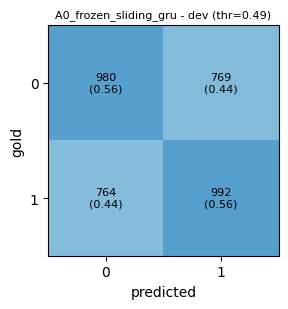

[A0_frozen_sliding_gru] dev macro-F1 @0.5 = 0.5518 | tuned (thr=0.49) = 0.5626 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A0_frozen_sliding_gru/submission.zip


{'name': 'A0_frozen_sliding_gru',
 'technique': 'frozen Phase-1 encoder + sliding/GRU head',
 'phase1_model': 'encdec',
 'trainable_params': 1186307,
 'total_params': 55722499,
 'train_seconds': 2485.815325021744,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=3; dev_infer_sec=805.2; test_pos_rate=0.503; refit=False; ',
 'submitted': False,
 'time': '2026-10-18 09:26',
 'dev_F1_thr0.5': 0.5518,
 'dev_F1_tuned': 0.5626,
 'thr': 0.49,
 'dev_P': 0.5626,
 'dev_R': 0.5626,
 'dev_acc': 0.5626,
 'dev_F1_c0': 0.5611,
 'dev_F1_c1': 0.5641}

In [ ]:
# A0) diagnostic: frozen Phase-1 encoder, sliding windows + hierarchical head
run_cjpe("A0_frozen_sliding_gru", "frozen Phase-1 encoder + sliding/GRU head", {"method": "frozen", "epochs": 10})

[A1_lora_head] method=lora view=head pool=mean trainable=1.05M / total=55.58M
{"epoch": 1, "train_loss": 0.7141, "sec": 463.1, "dev_F1": 0.4172, "dev_P": 0.6268, "dev_R": 0.5316, "dev_acc": 0.52}
{"epoch": 2, "train_loss": 0.7102, "sec": 455.8, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6982, "sec": 458.1, "dev_F1": 0.3363, "dev_P": 0.255, "dev_R": 0.4935, "dev_acc": 0.5067}
{"epoch": 4, "train_loss": 0.6912, "sec": 431.6, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


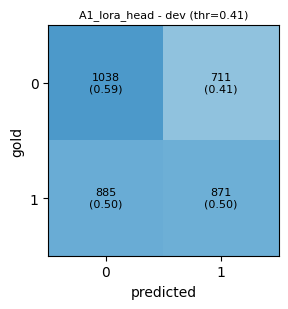

[A1_lora_head] dev macro-F1 @0.5 = 0.3962 | tuned (thr=0.41) = 0.5436 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A1_lora_head/submission.zip


{'name': 'A1_lora_head',
 'technique': 'LoRA | head-512 truncation',
 'phase1_model': 'encdec',
 'trainable_params': 1047554,
 'total_params': 55583746,
 'train_seconds': 1842.8777799606323,
 'notes': 'view=head; pool=mean; stride=384; best_epoch=1; dev_infer_sec=101.2; test_pos_rate=0.455; refit=False; ',
 'submitted': False,
 'time': '2026-10-18 09:59',
 'dev_F1_thr0.5': 0.3962,
 'dev_F1_tuned': 0.5436,
 'thr': 0.41,
 'dev_P': 0.5452,
 'dev_R': 0.5447,
 'dev_acc': 0.5447,
 'dev_F1_c0': 0.5654,
 'dev_F1_c1': 0.5219}

In [ ]:
# A1) first 512 tokens only (classic truncation)
run_cjpe("A1_lora_head", "LoRA | head-512 truncation", {"method": "lora", "view": "head", "pool": "mean"})

[A2_lora_tail] method=lora view=tail pool=mean trainable=1.05M / total=55.58M
{"epoch": 1, "train_loss": 0.7178, "sec": 445.7, "dev_F1": 0.4131, "dev_P": 0.5909, "dev_R": 0.5247, "dev_acc": 0.5133}
{"epoch": 2, "train_loss": 0.7016, "sec": 402.4, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6979, "sec": 396.1, "dev_F1": 0.4602, "dev_P": 0.5238, "dev_R": 0.5149, "dev_acc": 0.5067}
{"epoch": 4, "train_loss": 0.6958, "sec": 392.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 5, "train_loss": 0.6817, "sec": 389.5, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 6, "train_loss": 0.6794, "sec": 392.0, "dev_F1": 0.3676, "dev_P": 0.676, "dev_R": 0.5161, "dev_acc": 0.5033}
early stop


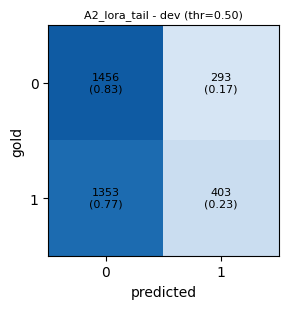

[A2_lora_tail] dev macro-F1 @0.5 = 0.4838 | tuned (thr=0.50) = 0.4838 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A2_lora_tail/submission.zip


{'name': 'A2_lora_tail',
 'technique': 'LoRA | tail-512 truncation',
 'phase1_model': 'encdec',
 'trainable_params': 1047554,
 'total_params': 55583746,
 'train_seconds': 2467.5084850788116,
 'notes': 'view=tail; pool=mean; stride=384; best_epoch=3; dev_infer_sec=96.8; test_pos_rate=0.204; refit=False; ',
 'submitted': False,
 'time': '2026-10-18 10:42',
 'dev_F1_thr0.5': 0.4838,
 'dev_F1_tuned': 0.4838,
 'thr': 0.5,
 'dev_P': 0.5487,
 'dev_R': 0.531,
 'dev_acc': 0.5304,
 'dev_F1_c0': 0.6389,
 'dev_F1_c1': 0.3287}

In [ ]:
# A2) last 512 tokens only (the end of a judgment usually contains the order / conclusion)
run_cjpe("A2_lora_tail", "LoRA | tail-512 truncation", {"method": "lora", "view": "tail", "pool": "mean"})

[A3_lora_headtail] method=lora view=headtail pool=mean trainable=1.05M / total=55.58M
{"epoch": 1, "train_loss": 0.7149, "sec": 467.7, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.7108, "sec": 468.6, "dev_F1": 0.3392, "dev_P": 0.2567, "dev_R": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.7007, "sec": 473.3, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.6904, "sec": 477.3, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 5, "train_loss": 0.6877, "sec": 474.9, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


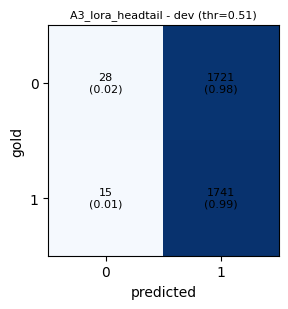

[A3_lora_headtail] dev macro-F1 @0.5 = 0.3338 | tuned (thr=0.51) = 0.3493 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A3_lora_headtail/submission.zip


{'name': 'A3_lora_headtail',
 'technique': 'LoRA | head+tail windows, mean pool',
 'phase1_model': 'encdec',
 'trainable_params': 1047554,
 'total_params': 55583746,
 'train_seconds': 2435.6566355228424,
 'notes': 'view=headtail; pool=mean; stride=384; best_epoch=2; dev_infer_sec=172.6; test_pos_rate=0.986; refit=False; ',
 'submitted': False,
 'time': '2026-10-18 11:27',
 'dev_F1_thr0.5': 0.3338,
 'dev_F1_tuned': 0.3493,
 'thr': 0.51,
 'dev_P': 0.577,
 'dev_R': 0.5037,
 'dev_acc': 0.5047,
 'dev_F1_c0': 0.0312,
 'dev_F1_c1': 0.6673}

In [ ]:
# A3) head + tail windows
run_cjpe("A3_lora_headtail", "LoRA | head+tail windows, mean pool", {"method": "lora", "view": "headtail", "pool": "mean"})

[A4_lora_sliding_mean] method=lora view=sliding pool=mean trainable=1.05M / total=55.58M
{"epoch": 1, "train_loss": 0.7175, "sec": 1090.3, "dev_F1": 0.354, "dev_P": 0.6458, "dev_R": 0.5096, "dev_acc": 0.4967}
{"epoch": 2, "train_loss": 0.7101, "sec": 1084.8, "dev_F1": 0.3392, "dev_P": 0.2567, "dev_R": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6979, "sec": 1083.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.6905, "sec": 1069.6, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


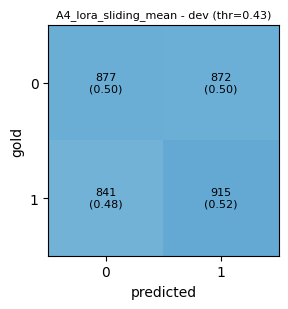

[A4_lora_sliding_mean] dev macro-F1 @0.5 = 0.3575 | tuned (thr=0.43) = 0.5112 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A4_lora_sliding_mean/submission.zip
[A5_lora_sliding_attn] method=lora view=sliding pool=attn trainable=1.11M / total=55.65M
{"epoch": 1, "train_loss": 0.7271, "sec": 1083.8, "dev_F1": 0.3523, "dev_P": 0.5782, "dev_R": 0.5061, "dev_acc": 0.4933}
{"epoch": 2, "train_loss": 0.7116, "sec": 1085.7, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.7009, "sec": 1084.9, "dev_F1": 0.3392, "dev_P": 0.2567, "dev_R": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6909, "sec": 1072.0, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


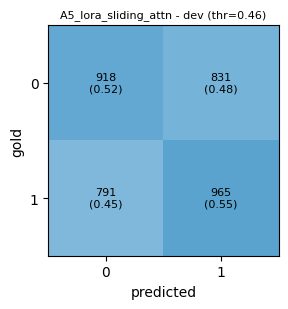

[A5_lora_sliding_attn] dev macro-F1 @0.5 = 0.3527 | tuned (thr=0.46) = 0.5371 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A5_lora_sliding_attn/submission.zip
[A6_lora_sliding_gru] method=lora view=sliding pool=gru trainable=2.03M / total=56.57M
{"epoch": 1, "train_loss": 0.7034, "sec": 1092.0, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.703, "sec": 1091.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6933, "sec": 1088.4, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.69, "sec": 1080.7, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


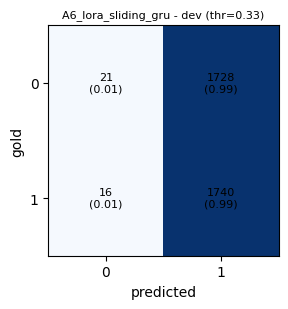

[A6_lora_sliding_gru] dev macro-F1 @0.5 = 0.3329 | tuned (thr=0.33) = 0.3448 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A6_lora_sliding_gru/submission.zip


{'name': 'A6_lora_sliding_gru',
 'technique': 'LoRA | sliding windows, hierarchical BiGRU+attention',
 'phase1_model': 'encdec',
 'trainable_params': 2034179,
 'total_params': 56570371,
 'train_seconds': 4649.928740739822,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=1; dev_infer_sec=889.2; test_pos_rate=0.987; refit=False; ',
 'submitted': False,
 'time': '2026-10-18 16:22',
 'dev_F1_thr0.5': 0.3329,
 'dev_F1_tuned': 0.3448,
 'thr': 0.33,
 'dev_P': 0.5346,
 'dev_R': 0.5014,
 'dev_acc': 0.5024,
 'dev_F1_c0': 0.0235,
 'dev_F1_c1': 0.6662}

In [ ]:
# A4-A6) sliding windows (25% overlap), three aggregators: mean -> attention -> hierarchical BiGRU+attention
run_cjpe("A4_lora_sliding_mean", "LoRA | sliding windows, mean pool", {"method": "lora", "view": "sliding", "pool": "mean"})
run_cjpe("A5_lora_sliding_attn", "LoRA | sliding windows, attention pool", {"method": "lora", "view": "sliding", "pool": "attn"})
run_cjpe("A6_lora_sliding_gru", "LoRA | sliding windows, hierarchical BiGRU+attention", {"method": "lora", "view": "sliding", "pool": "gru"})

[A7a_lora_sliding_last8] method=lora view=sliding_last pool=gru trainable=2.03M / total=56.57M
{"epoch": 1, "train_loss": 0.7024, "sec": 1091.3, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6975, "sec": 1095.6, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6918, "sec": 1094.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.6887, "sec": 1079.8, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


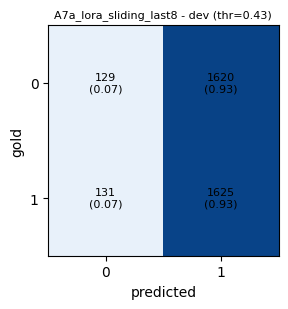

[A7a_lora_sliding_last8] dev macro-F1 @0.5 = 0.3329 | tuned (thr=0.43) = 0.3891 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A7a_lora_sliding_last8/submission.zip
[A7b_lora_sliding_headtail8] method=lora view=sliding_headtail pool=gru trainable=2.03M / total=56.57M
{"epoch": 1, "train_loss": 0.7051, "sec": 1092.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.7044, "sec": 1095.0, "dev_F1": 0.3392, "dev_P": 0.2567, "dev_R": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6951, "sec": 1090.6, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.6889, "sec": 1078.6, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 5, "train_loss": 0.6861, "sec": 1097.8, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


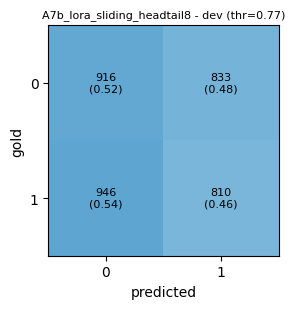

[A7b_lora_sliding_headtail8] dev macro-F1 @0.5 = 0.3338 | tuned (thr=0.77) = 0.4920 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A7b_lora_sliding_headtail8/submission.zip


{'name': 'A7b_lora_sliding_headtail8',
 'technique': 'LoRA | first-4 + last-4 windows, BiGRU',
 'phase1_model': 'encdec',
 'trainable_params': 2034179,
 'total_params': 56570371,
 'train_seconds': 5694.658314466476,
 'notes': 'view=sliding_headtail; pool=gru; stride=384; best_epoch=2; dev_infer_sec=563.3; test_pos_rate=0.483; refit=False; ',
 'submitted': False,
 'time': '2026-10-18 19:40',
 'dev_F1_thr0.5': 0.3338,
 'dev_F1_tuned': 0.492,
 'thr': 0.77,
 'dev_P': 0.4925,
 'dev_R': 0.4925,
 'dev_acc': 0.4924,
 'dev_F1_c0': 0.5073,
 'dev_F1_c1': 0.4766}

In [ ]:
# A7) section selection: only the last 8 windows / first+last 4 windows  (hierarchical head)
run_cjpe("A7a_lora_sliding_last8", "LoRA | last-8 windows, BiGRU", {"method": "lora", "view": "sliding_last", "pool": "gru", "k_last": 8})
run_cjpe("A7b_lora_sliding_headtail8", "LoRA | first-4 + last-4 windows, BiGRU", {"method": "lora", "view": "sliding_headtail", "pool": "gru", "k_last": 8})

[A8a_lora_sliding_nooverlap] method=lora view=sliding pool=gru trainable=2.03M / total=56.57M
{"epoch": 1, "train_loss": 0.7039, "sec": 1051.1, "dev_F1": 0.3763, "dev_P": 0.5586, "dev_R": 0.5076, "dev_acc": 0.52}
{"epoch": 2, "train_loss": 0.7043, "sec": 1047.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6912, "sec": 1046.7, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.6886, "sec": 1030.6, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


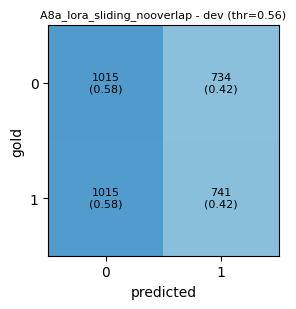

[A8a_lora_sliding_nooverlap] dev macro-F1 @0.5 = 0.3545 | tuned (thr=0.56) = 0.4979 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A8a_lora_sliding_nooverlap/submission.zip
[A8b_lora_sliding_overlap50] method=lora view=sliding pool=gru trainable=2.03M / total=56.57M
{"epoch": 1, "train_loss": 0.7042, "sec": 1144.7, "dev_F1": 0.3392, "dev_P": 0.2567, "dev_R": 0.5, "dev_acc": 0.5133}
{"epoch": 2, "train_loss": 0.7004, "sec": 1141.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6945, "sec": 1143.9, "dev_F1": 0.3392, "dev_P": 0.2567, "dev_R": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6909, "sec": 1134.0, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


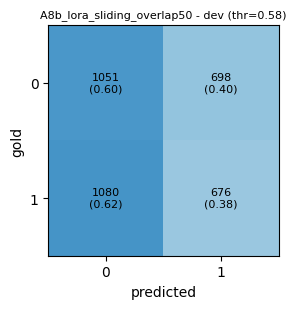

In [ ]:
# A8) overlap study: no overlap (stride = chunk_len-2) vs 50% overlap (stride ~ half a window); A6 used stride 384
run_cjpe("A8a_lora_sliding_nooverlap", "LoRA | sliding, stride 510 (no overlap), BiGRU", {"method": "lora", "view": "sliding", "pool": "gru", "stride": 510})
run_cjpe("A8b_lora_sliding_overlap50", "LoRA | sliding, stride 255 (50% overlap), BiGRU", {"method": "lora", "view": "sliding", "pool": "gru", "stride": 255, "eval_chunks": 36})

[A9_lora_sliding_gru_nopos] method=lora view=sliding pool=gru trainable=2.03M / total=56.57M
{"epoch": 1, "train_loss": 0.705, "sec": 1066.8, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.7033, "sec": 1068.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6941, "sec": 1067.9, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.6892, "sec": 1058.6, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
early stop


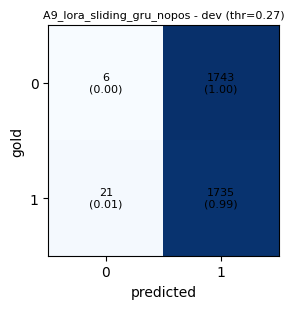

[A9_lora_sliding_gru_nopos] dev macro-F1 @0.5 = 0.3329 | tuned (thr=0.27) = 0.3349 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/A9_lora_sliding_gru_nopos/submission.zip


{'name': 'A9_lora_sliding_gru_nopos',
 'technique': 'LoRA | sliding, BiGRU, no position features',
 'phase1_model': 'encdec',
 'trainable_params': 2034179,
 'total_params': 56570371,
 'train_seconds': 4559.663735866547,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=1; dev_infer_sec=871.3; test_pos_rate=0.995; refit=False; ',
 'submitted': False,
 'time': '2026-10-19 03:45',
 'dev_F1_thr0.5': 0.3329,
 'dev_F1_tuned': 0.3349,
 'thr': 0.27,
 'dev_P': 0.3605,
 'dev_R': 0.4957,
 'dev_acc': 0.4967,
 'dev_F1_c0': 0.0068,
 'dev_F1_c1': 0.663}

In [ ]:
# A9) is the document-length / position feature a shortcut? same as A6 but without position features
run_cjpe("A9_lora_sliding_gru_nopos", "LoRA | sliding, BiGRU, no position features", {"method": "lora", "view": "sliding", "pool": "gru", "pos_feat": False})

### Part B – six different adaptation techniques
Set `BEST_REP` from your Part-A evidence (compare dev macro-F1 in the registry; with a small dev set differences of a point or two are noise), then run B1–B6. B1 is kept in memory as the KD teacher.

In [ ]:
BEST_REP = dict(view="sliding", pool="gru", method="frozen")        # <- EDIT after Part A (e.g. view="sliding_headtail", pool="attn", stride=255 ...)
print(BEST_REP)

{'view': 'sliding', 'pool': 'gru', 'method': 'frozen'}


[B1_full_ft] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 348.5, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 345.3, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 345.5, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 341.7, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 346.2, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 345.2, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


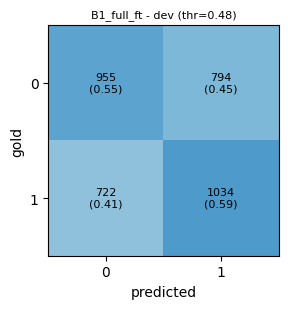

[B1_full_ft] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B1_full_ft/submission.zip


{'name': 'B1_full_ft',
 'technique': 'full fine-tuning',
 'phase1_model': 'encdec',
 'trainable_params': 1186307,
 'total_params': 55722499,
 'train_seconds': 2469.5502383708954,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=3; dev_infer_sec=788.8; test_pos_rate=0.519; refit=False; ',
 'submitted': False,
 'time': '2026-10-19 04:45',
 'dev_F1_thr0.5': 0.5125,
 'dev_F1_tuned': 0.5673,
 'thr': 0.48,
 'dev_P': 0.5676,
 'dev_R': 0.5674,
 'dev_acc': 0.5675,
 'dev_F1_c0': 0.5575,
 'dev_F1_c1': 0.577}

In [ ]:
# B1) full fine-tuning (kept in memory as KD teacher)
run_cjpe("B1_full_ft", "full fine-tuning", {"method": "full", **BEST_REP}, keep=True)

[B2_partial_top3] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 341.9, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 341.6, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 341.2, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 336.7, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 342.1, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 340.9, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


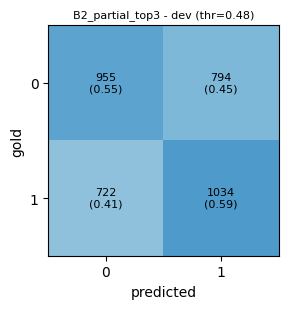

[B2_partial_top3] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B2_partial_top3/submission.zip


{'name': 'B2_partial_top3',
 'technique': 'partial fine-tuning (top 3 encoder layers)',
 'phase1_model': 'encdec',
 'trainable_params': 1186307,
 'total_params': 55722499,
 'train_seconds': 2440.1616904735565,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=3; dev_infer_sec=786.9; test_pos_rate=0.519; refit=False; ',
 'submitted': False,
 'time': '2026-10-19 05:44',
 'dev_F1_thr0.5': 0.5125,
 'dev_F1_tuned': 0.5673,
 'thr': 0.48,
 'dev_P': 0.5676,
 'dev_R': 0.5674,
 'dev_acc': 0.5675,
 'dev_F1_c0': 0.5575,
 'dev_F1_c1': 0.577}

In [ ]:
# B2) partial / layer-wise fine-tuning: top 3 encoder layers
run_cjpe("B2_partial_top3", "partial fine-tuning (top 3 encoder layers)", {"method": "partial", "unfreeze_top": 3, **BEST_REP})

[B3_gradual_unfreeze] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 339.1, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 338.6, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 338.8, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 335.6, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 341.4, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 340.1, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}


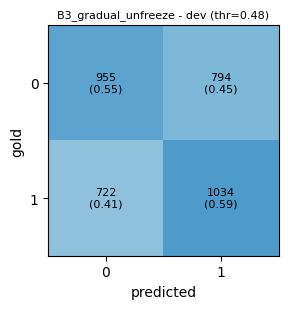

[B3_gradual_unfreeze] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B3_gradual_unfreeze/submission.zip


{'name': 'B3_gradual_unfreeze',
 'technique': 'gradual layer-wise unfreezing (+2 layers/epoch)',
 'phase1_model': 'encdec',
 'trainable_params': 1186307,
 'total_params': 55722499,
 'train_seconds': 2428.932599544525,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=3; dev_infer_sec=785.8; test_pos_rate=0.519; refit=False; ',
 'submitted': False,
 'time': '2026-10-19 06:44',
 'dev_F1_thr0.5': 0.5125,
 'dev_F1_tuned': 0.5673,
 'thr': 0.48,
 'dev_P': 0.5676,
 'dev_R': 0.5674,
 'dev_acc': 0.5675,
 'dev_F1_c0': 0.5575,
 'dev_F1_c1': 0.577}

In [ ]:
# B3) layer-wise unfreezing schedule: head only -> +2 layers/epoch (top-down). patience=6 so early stopping can't fire before layers are released.
run_cjpe("B3_gradual_unfreeze", "gradual layer-wise unfreezing (+2 layers/epoch)", {"method": "gradual", "epochs": 6, "patience": 6, **BEST_REP})

In [ ]:
# B4) LoRMA+ (compulsory)
run_cjpe("B4_lorma", "LoRMA+ (multiplicative low-rank, additive inflation)", {"method": "lorma", **BEST_REP})

[B4_lorma] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 337.8, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 337.8, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 338.5, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 336.3, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 341.7, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 341.2, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


[B5_adapter] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 337.8, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 338.0, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 338.1, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 335.2, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 341.0, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 339.7, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


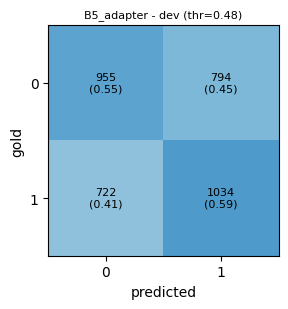

[B5_adapter] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B5_adapter/submission.zip


{'name': 'B5_adapter',
 'technique': 'Houlsby bottleneck adapters (dim 64)',
 'phase1_model': 'encdec',
 'trainable_params': 1186307,
 'total_params': 55722499,
 'train_seconds': 2425.2031257152557,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=3; dev_infer_sec=786.1; test_pos_rate=0.519; refit=False; ',
 'submitted': False,
 'time': '2026-10-19 08:42',
 'dev_F1_thr0.5': 0.5125,
 'dev_F1_tuned': 0.5673,
 'thr': 0.48,
 'dev_P': 0.5676,
 'dev_R': 0.5674,
 'dev_acc': 0.5675,
 'dev_F1_c0': 0.5575,
 'dev_F1_c1': 0.577}

In [ ]:
# B5) Houlsby-style bottleneck adapters (after attention-out and FFN-out)
run_cjpe("B5_adapter", "Houlsby bottleneck adapters (dim 64)", {"method": "adapter", **BEST_REP})

[B6_kd_student] method=frozen view=sliding pool=gru trainable=1.19M / total=34.75M
{"epoch": 1, "train_loss": 0.3487, "sec": 462.9, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.3454, "sec": 464.4, "dev_F1": 0.5401, "dev_P": 0.5744, "dev_R": 0.5621, "dev_acc": 0.5567}
{"epoch": 3, "train_loss": 0.3438, "sec": 463.8, "dev_F1": 0.4329, "dev_P": 0.6286, "dev_R": 0.5379, "dev_acc": 0.5267}
{"epoch": 4, "train_loss": 0.3426, "sec": 460.7, "dev_F1": 0.411, "dev_P": 0.5752, "dev_R": 0.5213, "dev_acc": 0.51}
{"epoch": 5, "train_loss": 0.3403, "sec": 467.4, "dev_F1": 0.3926, "dev_P": 0.592, "dev_R": 0.5186, "dev_acc": 0.5067}
early stop


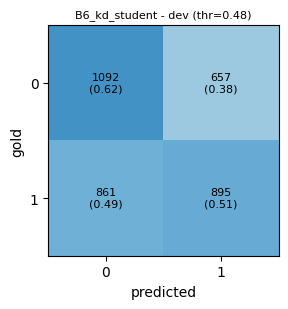

[B6_kd_student] dev macro-F1 @0.5 = 0.5490 | tuned (thr=0.48) = 0.5655 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B6_kd_student/submission.zip
[B6b_student_no_kd] method=frozen view=sliding pool=gru trainable=1.19M / total=34.75M
{"epoch": 1, "train_loss": 0.6987, "sec": 163.0, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6919, "sec": 163.0, "dev_F1": 0.5637, "dev_P": 0.5864, "dev_R": 0.5753, "dev_acc": 0.58}
{"epoch": 3, "train_loss": 0.6854, "sec": 162.9, "dev_F1": 0.5365, "dev_P": 0.5366, "dev_R": 0.5366, "dev_acc": 0.5367}
{"epoch": 4, "train_loss": 0.6851, "sec": 161.1, "dev_F1": 0.4253, "dev_P": 0.6536, "dev_R": 0.5382, "dev_acc": 0.5267}
{"epoch": 5, "train_loss": 0.6787, "sec": 163.8, "dev_F1": 0.3965, "dev_P": 0.6429, "dev_R": 0.5254, "dev_acc": 0.5133}
early stop


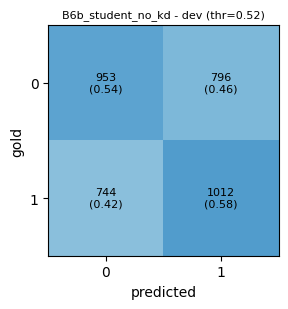

[B6b_student_no_kd] dev macro-F1 @0.5 = 0.5428 | tuned (thr=0.52) = 0.5605 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B6b_student_no_kd/submission.zip


{'name': 'B6b_student_no_kd',
 'technique': '4-layer student, hard labels only (KD ablation)',
 'phase1_model': 'encdec (bottom 4 layers)',
 'trainable_params': 1186307,
 'total_params': 34745859,
 'train_seconds': 964.1402547359467,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=2; dev_infer_sec=357.9; test_pos_rate=0.526; refit=False; ',
 'submitted': False,
 'time': '2026-10-19 09:57',
 'dev_F1_thr0.5': 0.5428,
 'dev_F1_tuned': 0.5605,
 'thr': 0.52,
 'dev_P': 0.5607,
 'dev_R': 0.5606,
 'dev_acc': 0.5606,
 'dev_F1_c0': 0.5531,
 'dev_F1_c1': 0.5679}

In [ ]:
# B6) knowledge distillation: teacher = B1 (9-layer encoder, full FT) -> student = bottom-4 Phase-1 encoder layers, trained on teacher logits + hard labels
teacher = MODELS["B1_full_ft"]
run_cjpe("B6_kd_student", "KD: 9-layer teacher -> 4-layer student (CE + KL on logits)",
         {"method": "full", "kd_alpha": 0.5, "kd_T": 2.0, **BEST_REP}, n_layers=4, teacher=teacher, notes="teacher=B1_full_ft")
# For a fair KD comparison also run the same 4-layer student WITHOUT the teacher:
run_cjpe("B6b_student_no_kd", "4-layer student, hard labels only (KD ablation)", {"method": "full", **BEST_REP}, n_layers=4)

[B7a_lora] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 338.7, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 338.7, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 339.1, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 336.0, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 341.8, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 340.2, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


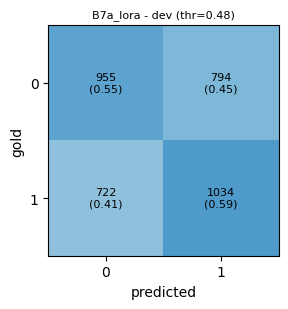

[B7a_lora] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B7a_lora/submission.zip
[B7b_rslora] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 337.7, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 338.7, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 338.6, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 337.2, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 340.9, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 340.6, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


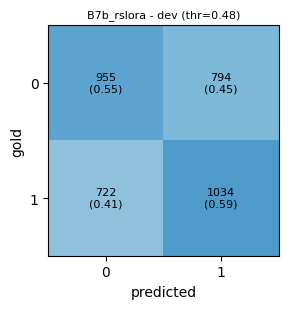

[B7b_rslora] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B7b_rslora/submission.zip
[B7c_ia3] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 338.9, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 338.9, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 339.5, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 336.2, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 342.0, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 340.7, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


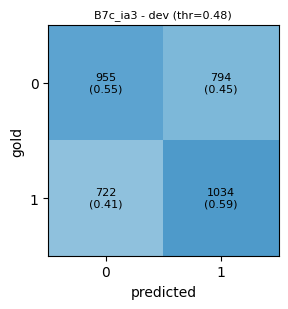

[B7c_ia3] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B7c_ia3/submission.zip
[B7d_norm] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 338.9, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 338.1, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 339.5, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 335.9, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 341.7, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 341.8, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


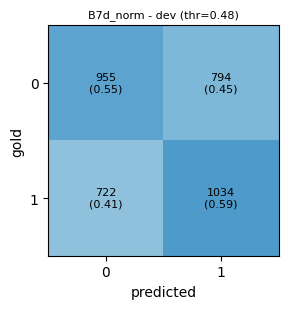

[B7d_norm] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B7d_norm/submission.zip
[B7e_prompt] method=frozen view=sliding pool=gru trainable=1.19M / total=55.72M
{"epoch": 1, "train_loss": 0.7025, "sec": 338.5, "dev_F1": 0.3274, "dev_P": 0.2433, "dev_R": 0.5, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6954, "sec": 338.7, "dev_F1": 0.5308, "dev_P": 0.5549, "dev_R": 0.5481, "dev_acc": 0.5433}
{"epoch": 3, "train_loss": 0.689, "sec": 339.4, "dev_F1": 0.5325, "dev_P": 0.6202, "dev_R": 0.578, "dev_acc": 0.57}
{"epoch": 4, "train_loss": 0.6803, "sec": 335.9, "dev_F1": 0.4993, "dev_P": 0.5838, "dev_R": 0.5516, "dev_acc": 0.5433}
{"epoch": 5, "train_loss": 0.6764, "sec": 341.5, "dev_F1": 0.4523, "dev_P": 0.6032, "dev_R": 0.5404, "dev_acc": 0.53}
{"epoch": 6, "train_loss": 0.6749, "sec": 341.9, "dev_F1": 0.4971, "dev_P": 0.5865, "dev_R": 0.5518, "dev_acc": 0.5433}
early stop


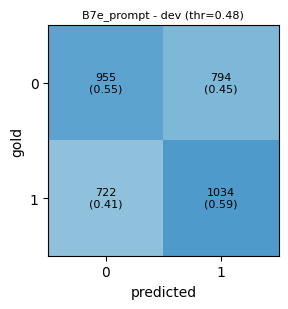

[B7e_prompt] dev macro-F1 @0.5 = 0.5125 | tuned (thr=0.48) = 0.5673 | zip: /content/drive/MyDrive/Phase4_Court_Judgment_Prediction/experiments/B7e_prompt/submission.zip


{'name': 'B7e_prompt',
 'technique': 'prompt tuning (16 soft tokens)',
 'phase1_model': 'encdec',
 'trainable_params': 1186307,
 'total_params': 55722499,
 'train_seconds': 2431.5354447364807,
 'notes': 'view=sliding; pool=gru; stride=384; best_epoch=3; dev_infer_sec=786.6; test_pos_rate=0.519; refit=False; ',
 'submitted': False,
 'time': '2026-10-19 14:54',
 'dev_F1_thr0.5': 0.5125,
 'dev_F1_tuned': 0.5673,
 'thr': 0.48,
 'dev_P': 0.5676,
 'dev_R': 0.5674,
 'dev_acc': 0.5675,
 'dev_F1_c0': 0.5575,
 'dev_F1_c1': 0.577}

In [ ]:
# B7) optional extras (use if you want more than six, or to compare with Phase 3): LoRA, rsLoRA, IA3, norm-gain tuning (BitFit analogue), prompt tuning
run_cjpe("B7a_lora", "LoRA r=8 on all attention+FFN linears", {"method": "lora", **BEST_REP})
run_cjpe("B7b_rslora", "rsLoRA (alpha/sqrt(r) scaling)", {"method": "rslora", "r": 16, **BEST_REP})
run_cjpe("B7c_ia3", "IA3 (learned scaling of K, V, FFN activations)", {"method": "ia3", **BEST_REP})
run_cjpe("B7d_norm", "norm-gain tuning (BitFit analogue; model has no biases)", {"method": "norm", **BEST_REP})
run_cjpe("B7e_prompt", "prompt tuning (16 soft tokens)", {"method": "prompt", **BEST_REP})

### Part C – which part of the judgment does a trained model use? / error analysis

In [ ]:
# Re-score dev with different windows at inference time using the full-FT model from B1 (no retraining).
# A model trained on sliding windows evaluated on `head` or `tail` alone shows how much each section contributes.
abl = inference_view_ablation(MODELS["B1_full_ft"], DATA["dev"])
abl.to_csv(os.path.join(OUTPUT_DIR, "inference_view_ablation_B1.csv"), index=False)
display(abl) if "display" in dir() else print(abl)

     inference_view       P       R      F1  accuracy   F1_c0   F1_c1
0              head  0.5441  0.5051  0.3641    0.5041  0.6625  0.0656
1              tail  0.5575  0.5037  0.3516    0.5027  0.6646  0.0386
2          headtail  0.5798  0.5133  0.3849    0.5124  0.6650  0.1048
3  sliding_headtail  0.5808  0.5481  0.4970    0.5475  0.6564  0.3375
4      sliding_last  0.5758  0.5444  0.4915    0.5438  0.6546  0.3284
5           sliding  0.5762  0.5518  0.5125    0.5512  0.6499  0.3750


In [ ]:
# False positives / false negatives by document length (token-length quartiles) for any logged run.
def error_by_length(name, q=4):
    df = pd.read_csv(os.path.join(OUTPUT_DIR, "experiments", name, "dev_preds.csv"))
    df["len_bin"] = pd.qcut(df["n_tok"], q, duplicates="drop")
    def stats(g):
        return pd.Series({"n": len(g), "acc": (g.y == g.pred).mean(), "FP": ((g.y == 0) & (g.pred == 1)).sum(),
                          "FN": ((g.y == 1) & (g.pred == 0)).sum(), "frac_label_1": g.y.mean()})
    return df.groupby("len_bin", observed=True).apply(stats).round(3)
display(error_by_length("B1_full_ft")) if "display" in dir() else print(error_by_length("B1_full_ft"))

                       n    acc     FP     FN  frac_label_1
len_bin                                                    
(95.999, 2237.0]   877.0  0.582  160.0  207.0         0.509
(2237.0, 3516.0]   876.0  0.570  196.0  181.0         0.511
(3516.0, 5576.0]   877.0  0.540  211.0  192.0         0.480
(5576.0, 20000.0]  875.0  0.578  227.0  142.0         0.504


/tmp/ipykernel_5354/1909145628.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("len_bin", observed=True).apply(stats).round(3)


## 10. Summary table and training curves (ancillary; interpret the results yourself)

                          name  \
0        A0_frozen_sliding_gru   
1                 A1_lora_head   
2                 A2_lora_tail   
3             A3_lora_headtail   
4         A4_lora_sliding_mean   
5         A5_lora_sliding_attn   
6          A6_lora_sliding_gru   
7       A7a_lora_sliding_last8   
8   A7b_lora_sliding_headtail8   
9   A8a_lora_sliding_nooverlap   
10  A8b_lora_sliding_overlap50   
11   A9_lora_sliding_gru_nopos   
12                  B1_full_ft   
13             B2_partial_top3   
14         B3_gradual_unfreeze   
15                    B4_lorma   
16                  B5_adapter   
17               B6_kd_student   
18           B6b_student_no_kd   
19                    B7a_lora   
20                  B7b_rslora   
21                     B7c_ia3   
22                    B7d_norm   
23                  B7e_prompt   

                                            technique  trainable_params  \
0           frozen Phase-1 encoder + sliding/GRU head           1186307   

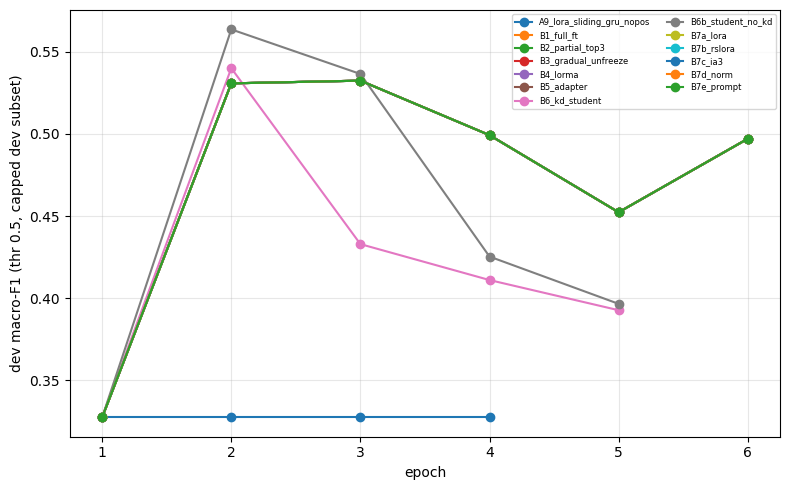

In [ ]:
reg = pd.DataFrame(registry)
cols = ["name", "technique", "trainable_params", "total_params", "dev_F1_thr0.5", "dev_F1_tuned", "thr", "dev_P", "dev_R", "dev_F1_c0", "dev_F1_c1", "train_seconds", "notes"]
shown = reg[[c for c in cols if c in reg.columns]]
display(shown) if "display" in dir() else print(shown)

fig, ax = plt.subplots(figsize=(8, 5))
for name, r in RUNS.items():
    h = pd.DataFrame(r["hist"])
    if "dev_F1" in h: ax.plot(h["epoch"], h["dev_F1"], marker="o", label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("dev macro-F1 (thr 0.5, capped dev subset)"); ax.legend(fontsize=6, ncol=2); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "dev_curves.png"), dpi=150); plt.show()

## Notes
* Early stopping uses macro-F1 at threshold 0.5 on a **capped dev subset** (`dev_cap`); the logged `dev_F1_thr0.5` / `dev_F1_tuned` come from the **full** dev set. The tuned threshold is fitted on that same dev set, so `dev_F1_tuned` is optimistic — treat it as an upper bound.
* Windows beyond `train_chunks` (training) / `eval_chunks` (inference) are subsampled (random in training, evenly spaced at inference); documents beyond `MAX_DOC_TOKENS` are trimmed to head+tail. Both are lossy — report them as limitations.
* `pos_feat` includes log document length, which can act as a shortcut; A9 measures that.
* Use `refit=True` for your final submissions to train on train+dev.
* Cite: Hu et al. 2021 (LoRA), Kalajdzievski 2023 (rsLoRA), Bihany et al. 2025 (LoRMA), Houlsby et al. 2019 (adapters), Ben Zaken et al. 2022 (BitFit), Liu et al. 2022 (IA³), Lester et al. 2021 (prompt tuning), Hinton et al. 2015 (distillation), Chen et al. 2016 (activation checkpointing).